# Do a few early tokens decide the algorithm? — demo notebook

Demo of the experiment script `method.py` behind *Prompt bans substitute, not just subtract*.
**Qwen3-8B** (bf16, thinking off) wrote Python solutions for two path-search tasks:

* **T1, unweighted grid path:** `solve(grid, start, goal)` returns any valid 4-neighbour path.
* **T2, weighted shortest path:** `solve(n, edges, s, t)` returns the shortest distance in a directed graph.

Each task was prompted with a neutral **baseline** prompt and with a **ban** prompt: *"Do not use breadth-first search (BFS)"* for T1 and *"Do not use Dijkstra's algorithm"* for T2. Each prompt has 10 paraphrases.

Under the baseline prompt the model essentially always writes the textbook algorithm: BFS on T1 and Dijkstra on T2, at every temperature tried. The experiment asks *where* that choice is made:

* **Fixed before generation starts.** The choice is already made at the last prompt token (the *read position*, **R**).
* **Decided at forking tokens.** The choice is made at a few tokens during generation. If so, raising the temperature only around those tokens would be a knob for algorithmic diversity.

To find out, it restarts generation from many prefixes of a sampled answer (a *base path*) and watches when the distribution of resulting algorithms stops changing. This is a Forking-Paths-style resampling screen.

**What this notebook runs** (CPU only, about 2–3 minutes at the original scale on 2 CPUs):

1. **Labeller test.** The sandboxed labeller (runtime tracer + AST rules + 40 hidden tests per task) runs on the 17 reference solutions.
2. **Pool re-labelling.** The same labeller runs on the 600 pool programs of the screened prompts. This reproduces the recorded labels and the baseline/ban label counts of the paper's Table 17.
3. **Commitment tokens.** The commitment-token rule runs on the 40 base paths.
4. **Detector sensitivity (T6).** The planted-change test checks the change-point detector.
5. **Screen readouts.** These come from `analysis/final.py`, computed over the 40 base paths and their 5,900 labelled continuations: agreement curves, permutation-calibrated change points, token-level forks and control positions (Tables 18 and 19).
6. **Verdict.** The pre-registered verdict rule is applied.

**What is not re-run:**

* **GPU generation.** About 10,000 Qwen3-8B samples (vLLM) are not regenerated. Their labelled records are loaded from `mini_demo_data.json`, which is one dataset of the artifact's output, `fork_screen_base_paths`.
* **Knob and probes.** The knob contrasts and the probe summary are taken from the stored run. They need GPU-generated knob samples and 790 MB of residual-stream states.
* **LLM judge.** It is not called. Its recorded verdicts on the 6 disputed programs are applied instead.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru, ruptures — NOT on Colab, always install
_pip('loguru==0.7.3', 'ruptures==1.1.10')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- original method.py import block (its `from common import ...` line follows once the package is written) ----
import argparse
import json
import os
import resource
import sys
import time
from pathlib import Path

from loguru import logger  # noqa: E402

# ---- additional imports for the notebook cells ----
import collections
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["datasets"][0]["dataset"], "-", len(examples), "base paths;", data["metadata"]["description"])
print("one example:", {k: (v if not isinstance(v, (dict, list)) or len(json.dumps(v)) < 90 else f"<{type(v).__name__}>")
                       for k, v in examples[1].items() if k != "input"})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
fork_screen_base_paths - 40 base paths; fork_screen_base_paths of full_method_out.json (40 base paths), each enriched with the pool and continuation labels that analysis/final.py:screen_readouts reads
one example: {'output': 'DFS', 'metadata_bp_id': 'T1|ban|0', 'metadata_agreement_curve': '<dict>', 'metadata_fixed_by': {'0': False, '8': False, '16': True, '32': True, '64': True}, 'metadata_commit_idx': 137, 'metadata_evidence_term': 'Stack', 'metadata_change_points': '<list>', 'predict_decided_at_R': 'False', 'predict_confirmed_forks': '[]', 'predict_change_point_brackets': '[[8, 12]]', 'metadata_task': 'T1', 'metadata_condition': 'ban', 'metadata_paraphrase_id': 0, 'metadata_base_path': '<dict>', 'metadata_o0_rows': '<list>', 'metadata_continuations': '<list>'}


## Configuration

All tunable sizes live here. **The values below are the artifact's original values**; at this scale the notebook runs in about 2–3 minutes on 2 CPUs, installs included. Each smaller value in `[...]` gives a faster, rougher run that still produces every output.

* **N_PARAS** — how many of the 10 paraphrases per task × condition to analyse. 10 means all 40 base paths.
* **N_RELABEL_PER_PROMPT** — how many pool programs per screened prompt go back through the sandbox. The baseline pools hold 20 programs per prompt and the ban pools 10, so 20 covers all 600.
* **N_PERM_\*** and **T6_\*** — permutation and simulation counts of the statistical tests.

In [5]:
N_PARAS = 10               # paraphrases per task x condition (original 10 -> 40 base paths)                [min 1]
N_RELABEL_PER_PROMPT = 20  # pool programs per prompt re-run through the sandboxed labeller
                           # (original: all of them = 20 per baseline prompt, 10 per ban prompt -> 600)   [min 1]
N_TEST_JOBS = 25           # labeller unit-test programs (17 references + 4 bad + 4 harness edge cases)    [min 1]
LABEL_WORKERS = 2          # parallel sandbox subprocesses (original LabelPool(workers=5); unit test 8)    [min 1]
N_PERM_BINSEG = 1000       # permutations per binary-segmentation split (original 1000)                   [min 19]
N_PERM_CHI2 = 2000         # permutations of the chi-square fork / control test (original 2000)           [min 19]
T6_N_SIM = 200             # planted-change simulations per TVD level (original 200)                      [min 1]
T6_N_PERM = 1000           # permutations per simulated detector call (original 1000)                     [min 19]

## 1. The artifact's code

The artifact is a small package:

* `method.py` and `common.py`
* `analysis/` (change points, final readouts)
* `labeller/` (tracer, AST rules, commitment lexicon)
* `harness/` (sandbox)
* `tasks/` (specs, hidden tests, references)
* `gen/` (vLLM stages, GPU only)

Each candidate program is labelled in its own `python -I harness/run_program.py ...` subprocess, so these modules must exist as files. The next cells write them **verbatim** into `./fork_screen/` with `%%writefile`. They are the same files the original run used, and nothing in them was edited.

In [6]:
PKG = Path("fork_screen")
for sub in ("analysis", "labeller", "harness", "tasks"):
    (PKG / sub).mkdir(parents=True, exist_ok=True)
    (PKG / sub / "__init__.py").touch()
sys.path.insert(0, str(PKG.resolve()))
print(sorted(str(p) for p in PKG.rglob("*")))

['fork_screen/analysis', 'fork_screen/analysis/__init__.py', 'fork_screen/harness', 'fork_screen/harness/__init__.py', 'fork_screen/labeller', 'fork_screen/labeller/__init__.py', 'fork_screen/tasks', 'fork_screen/tasks/__init__.py']


### `common.py` — shared utilities
* **Output folders:** `generations/`, `summaries/`, `logs/`, `figures/` and `states/`, created next to the module.
* **Logging:** loguru.
* **Seeding:** `stable_seed` hashes a request's identifying tuple with sha256. Every vLLM request was seeded this way.
* **JSONL I/O.**
* **Statistics:** Wilson intervals, the Hill number of order 1, entropy in bits, total variation distance (TVD) and Jensen–Shannon divergence. The Hill number is exp of the Shannon entropy of a label distribution, i.e. the *effective number of algorithms*.

In [7]:
%%writefile fork_screen/common.py
"""Shared utilities: paths, logging, hashing, JSONL IO, seeds and the small statistics used everywhere."""

from __future__ import annotations

import hashlib
import json
import math
import sys
import time
from pathlib import Path

import numpy as np
from loguru import logger

ROOT = Path(__file__).resolve().parent
GEN_DIR = ROOT / "generations"
SUM_DIR = ROOT / "summaries"
LOG_DIR = ROOT / "logs"
FIG_DIR = ROOT / "figures"
STATE_DIR = ROOT / "states"
for _d in (GEN_DIR, SUM_DIR, LOG_DIR, FIG_DIR, STATE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-8B"
TASKS = ("T1", "T2")
CONDITIONS = ("baseline", "ban")


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def stable_seed(*parts) -> int:
    h = hashlib.sha256(repr(tuple(parts)).encode()).hexdigest()
    return int(h, 16) % (2 ** 31 - 1000)


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def log_hash(name: str, path: Path) -> str:
    h = sha256_file(path)
    with open(LOG_DIR / "hashes.log", "a") as fh:
        fh.write(f"{time.strftime('%Y-%m-%dT%H:%M:%S')}\t{time.time():.3f}\t{name}\t{path.name}\t{h}\n")
    return h


def append_jsonl(path: Path, rows: list[dict]) -> None:
    with open(path, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def read_jsonl(path: Path) -> list[dict]:
    if not Path(path).exists():
        return []
    out = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue  # a line still being written by a concurrent appender
    return out


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float, float]:
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list) -> float:
    """Hill number of order 1 = exp(Shannon entropy in nats) of the label distribution."""
    if not labels:
        return float("nan")
    _, cnt = np.unique(np.asarray(labels, dtype=object).astype(str), return_counts=True)
    p = cnt / cnt.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def entropy_bits(counts) -> float:
    c = np.asarray(counts, dtype=float)
    if c.sum() <= 0:
        return float("nan")
    p = c[c > 0] / c.sum()
    return float(-(p * np.log2(p)).sum())


def tvd(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    return float(0.5 * np.abs(p / p.sum() - q / q.sum()).sum())


def js_div(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

Writing fork_screen/common.py


### `tasks/t1_grid.py` — task T1, unweighted grid path
* **`SPEC`** is the task text that follows the condition sentence in every prompt.
* **Catalogue:** BFS, DFS, bidirectional BFS, IDDFS, A*/greedy best-first and unit-weight Dijkstra. Two labels complete the outcome space: `other` and `no_code`.
* **Banned mode:** BFS.
* **Hidden tests:** a seeded generator of 40 cases: edge cases, random grids up to 30×30, DFS mazes, open grids, serpentine long paths and unreachable grids.
* **Validation:** a path validator, 9 reference solutions and two programs that must fail.

In [8]:
%%writefile fork_screen/tasks/t1_grid.py
"""T1: unweighted grid path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import random
from collections import deque

TASK_ID = "T1"
SPEC = (
    "Write a Python function solve(grid, start, goal) that finds a path on a 2-D grid. grid is a list of "
    "equal-length strings in which . is a free cell and # is an obstacle; start and goal are (row, col) tuples. "
    "Moves go up, down, left or right between free cells. Return any valid path as a list of (row, col) tuples "
    "from start to goal inclusive, or [] if the goal is unreachable or either endpoint is blocked. The grid has at "
    "most 30 rows and 30 columns. Use only the Python standard library. Return only one ```python code block "
    "containing the function and its imports."
)

# Catalogue (merged modes). 'other' and 'no_code' complete the outcome space.
CATALOGUE = ["BFS", "DFS", "bidirectional_BFS", "IDDFS", "astar_greedy", "unit_dijkstra"]
BANNED_MODE = "BFS"
CATALOGUE_DEFS = {
    "BFS": "breadth-first search with a FIFO queue (deque.popleft, list.pop(0) or queue.Queue), expanding cells in rings of increasing distance from the start",
    "DFS": "depth-first search with a LIFO stack or recursion (no growing depth limit), following one branch as deep as possible",
    "bidirectional_BFS": "a search with two frontiers grown from start and from goal that meet in the middle",
    "IDDFS": "iterative-deepening depth-first search: repeated depth-limited DFS with a growing depth limit",
    "astar_greedy": "A* or greedy best-first search: a priority queue ordered by a heuristic such as the Manhattan distance to the goal (with or without path cost)",
    "unit_dijkstra": "Dijkstra's algorithm on the grid: a priority queue keyed only by path length / distance from the start (no heuristic)",
    "other": "any other approach (e.g. brute-force enumeration, dynamic programming, flood fill without a queue, wall following)",
}


def free(grid: list[str], cell: tuple[int, int]) -> bool:
    r, c = cell
    return 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] == "."


def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict:
    """Reference BFS distances from start (used by the validator and the tracer)."""
    if not free(grid, start):
        return {}
    dist = {start: 0}
    q = deque([start])
    R, C = len(grid), len(grid[0])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                q.append((nr, nc))
    return dist


def reachable(grid: list[str], start, goal) -> bool:
    start, goal = tuple(start), tuple(goal)
    if not free(grid, start) or not free(grid, goal):
        return False
    return goal in bfs_dist(grid, start)


def validate(case: dict, out) -> tuple[bool, str]:
    grid, start, goal = case["grid"], tuple(case["start"]), tuple(case["goal"])
    exp_reach = case["reachable"]
    if not isinstance(out, (list, tuple)):
        return False, f"output is {type(out).__name__}, not a list"
    if not exp_reach:
        return (len(out) == 0, "expected [] (unreachable or blocked)" if len(out) else "ok")
    if len(out) == 0:
        return False, "returned [] but goal is reachable"
    try:
        path = [tuple(int(x) for x in cell) for cell in out]
    except (TypeError, ValueError):
        return False, "cells are not (row, col) pairs"
    if any(len(p) != 2 for p in path):
        return False, "cells are not (row, col) pairs"
    if path[0] != start:
        return False, "path does not start at start"
    if path[-1] != goal:
        return False, "path does not end at goal"
    for p in path:
        if not free(grid, p):
            return False, f"cell {p} is a wall or out of bounds"
    for a, b in zip(path, path[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False, f"non-adjacent step {a}->{b}"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_grid(rng: random.Random, R: int, C: int, dens: float) -> list[str]:
    return ["".join("#" if rng.random() < dens else "." for _ in range(C)) for _ in range(R)]


def _rand_free(rng: random.Random, grid: list[str]) -> tuple[int, int]:
    cells = [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]
    return rng.choice(cells)


def _maze(rng: random.Random, k: int) -> list[str]:
    """Random-DFS maze on a (2k+1) x (2k+1) grid."""
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    stack = [(1, 1)]
    g[1][1] = "."
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return ["".join(row) for row in g]


def _serpentine(R: int, C: int, flip: bool) -> list[str]:
    g = [["."] * C for _ in range(R)]
    for i, r in enumerate(range(1, R - 1, 2)):
        gap = (C - 1) if (i % 2 == 0) != flip else 0
        for c in range(C):
            if c != gap:
                g[r][c] = "#"
    return ["".join(row) for row in g]


def make_cases(seed: int = 1234) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, grid, start, goal):
        cases.append({"name": name, "grid": grid, "start": list(start), "goal": list(goal),
                      "reachable": reachable(grid, start, goal)})

    # 8 edge cases
    add("start_eq_goal", ["....", ".#..", "...."], (1, 2), (1, 2))
    add("start_on_wall", ["....", ".#..", "...."], (1, 1), (2, 3))
    add("goal_on_wall", ["....", ".#..", "...."], (0, 0), (1, 1))
    add("one_by_one", ["."], (0, 0), (0, 0))
    add("corridor_1xN", ["." * 25], (0, 0), (0, 24))
    add("corridor_Nx1", ["."] * 25, (24, 0), (0, 0))
    add("walled_goal", [".....", ".###.", ".#.#.", ".###.", "....."], (0, 0), (2, 2))
    add("enclosed_start", ["###....", "#.#....", "###....", "......."], (1, 1), (3, 6))
    # 12 random grids 10x10..30x30, density 0.10-0.35
    for i in range(12):
        R, C = rng.randint(10, 30), rng.randint(10, 30)
        g = _rand_grid(rng, R, C, rng.uniform(0.10, 0.35))
        s, t = _rand_free(rng, g), _rand_free(rng, g)
        add(f"random_{i}", g, s, t)
    # 6 random-DFS mazes up to 29x29
    for i, k in enumerate([5, 7, 9, 11, 13, 14]):
        g = _maze(rng, k)
        n = len(g)
        add(f"maze_{i}", g, (1, 1), (n - 2, n - 2))
    # 4 open 30x30
    for i in range(4):
        g = ["." * 30] * 30
        add(f"open_{i}", g, (rng.randrange(30), rng.randrange(30)), (rng.randrange(30), rng.randrange(30)))
    # 4 serpentine long-path grids
    for i, (R, C) in enumerate([(29, 29), (30, 30), (27, 30), (30, 25)]):
        g = _serpentine(R, C, flip=bool(i % 2))
        add(f"serpentine_{i}", g, (0, 0), (R - 1, 0 if (len(range(1, R - 1, 2)) % 2 == 0) else C - 1))
    # 6 large unreachable grids (a full wall separates the endpoints)
    for i in range(6):
        g = [list(row) for row in _rand_grid(rng, 30, 30, 0.15)]
        if i % 2 == 0:
            wc = rng.randint(8, 21)
            for r in range(30):
                g[r][wc] = "#"
            s = (rng.randrange(30), rng.randrange(0, wc))
            t = (rng.randrange(30), rng.randrange(wc + 1, 30))
        else:
            wr = rng.randint(8, 21)
            for c in range(30):
                g[wr][c] = "#"
            s = (rng.randrange(0, wr), rng.randrange(30))
            t = (rng.randrange(wr + 1, 30), rng.randrange(30))
        g[s[0]][s[1]] = "."
        g[t[0]][t[1]] = "."
        add(f"unreachable_{i}", ["".join(row) for row in g], s, t)
    # order small -> large so pathological programs fail early on cheap cases
    cases.sort(key=lambda cs: len(cs["grid"]) * len(cs["grid"][0]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_bfs"] = ("BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    sr, sc = start
    gr, gc = goal
    if grid[sr][sc] == '#' or grid[gr][gc] == '#':
        return []
    parent = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                q.append((nr, nc))
    return []
''')

REFERENCES["ref_bfs_listpop0"] = ("BFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] != '.' or grid[goal[0]][goal[1]] != '.':
        return []
    prev = {start: None}
    frontier = [start]
    while frontier:
        cur = frontier.pop(0)
        if cur == goal:
            out = []
            while cur is not None:
                out.append(cur)
                cur = prev[cur]
            return out[::-1]
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = cur[0] + dr, cur[1] + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                frontier.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_iter"] = ("DFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    stack = [start]
    parent = {start: None}
    while stack:
        cur = stack.pop()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                stack.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_rec"] = ("DFS", '''
import sys

def solve(grid, start, goal):
    sys.setrecursionlimit(10000)
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    seen = set()
    path = []

    def dfs(r, c):
        if (r, c) == goal:
            path.append((r, c))
            return True
        seen.add((r, c))
        path.append((r, c))
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in seen:
                if dfs(nr, nc):
                    return True
        path.pop()
        return False

    return path if dfs(start[0], start[1]) else []
''')

REFERENCES["ref_bidir_bfs"] = ("bidirectional_BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    if start == goal:
        return [start]
    par_s = {start: None}
    par_g = {goal: None}
    qs, qg = deque([start]), deque([goal])

    def nbrs(cell):
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                yield (nr, nc)

    def build(meet):
        left = []
        cur = meet
        while cur is not None:
            left.append(cur)
            cur = par_s[cur]
        left.reverse()
        cur = par_g[meet]
        while cur is not None:
            left.append(cur)
            cur = par_g[cur]
        return left

    while qs and qg:
        for _ in range(len(qs)):
            cur = qs.popleft()
            for nb in nbrs(cur):
                if nb not in par_s:
                    par_s[nb] = cur
                    if nb in par_g:
                        return build(nb)
                    qs.append(nb)
        for _ in range(len(qg)):
            cur = qg.popleft()
            for nb in nbrs(cur):
                if nb not in par_g:
                    par_g[nb] = cur
                    if nb in par_s:
                        return build(nb)
                    qg.append(nb)
    return []
''')

REFERENCES["ref_iddfs"] = ("IDDFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    n_free = sum(row.count('.') for row in grid)
    cut = [False]

    def dls(cell, depth, limit, path, best):
        if cell == goal:
            return True
        if depth == limit:
            cut[0] = True
            return False
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            nxt = (nr, nc)
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                if best.get(nxt, 10 ** 9) <= depth + 1:
                    continue
                best[nxt] = depth + 1
                path.append(nxt)
                if dls(nxt, depth + 1, limit, path, best):
                    return True
                path.pop()
        return False

    for limit in range(n_free + 1):
        path = [start]
        cut[0] = False
        if dls(start, 0, limit, path, {start: 0}):
            return path
        if not cut[0]:
            return []
    return []
''')

REFERENCES["ref_astar"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []

    def h(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    open_heap = [(h(start), 0, start)]
    g = {start: 0}
    came = {start: None}
    while open_heap:
        f, cost, cur = heapq.heappop(open_heap)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        if cost > g[cur]:
            continue
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                ng = cost + 1
                if ng < g.get((nr, nc), float('inf')):
                    g[(nr, nc)] = ng
                    came[(nr, nc)] = cur
                    heapq.heappush(open_heap, (ng + h((nr, nc)), ng, (nr, nc)))
    return []
''')

REFERENCES["ref_greedy"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    pq = [(abs(start[0] - goal[0]) + abs(start[1] - goal[1]), start)]
    came = {start: None}
    while pq:
        _, cur = heapq.heappop(pq)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in came:
                came[(nr, nc)] = cur
                heapq.heappush(pq, (abs(nr - goal[0]) + abs(nc - goal[1]), (nr, nc)))
    return []
''')

REFERENCES["ref_unit_dijkstra"] = ("unit_dijkstra", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    dist = {start: 0}
    prev = {start: None}
    pq = [(0, start)]
    while pq:
        d, cur = heapq.heappop(pq)
        if d > dist[cur]:
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                nd = d + 1
                if nd < dist.get((nr, nc), float('inf')):
                    dist[(nr, nc)] = nd
                    prev[(nr, nc)] = cur
                    heapq.heappush(pq, (nd, (nr, nc)))
    return []
''')

# Programs that are expected to FAIL (validator / limit tests), never part of the catalogue references.
BAD_PROGRAMS: dict[str, str] = {
    "bad_nonadjacent": '''
def solve(grid, start, goal):
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    return [start, goal] if start != goal else [start]
''',
    "bad_always_empty": '''
def solve(grid, start, goal):
    return []
''',
}

Writing fork_screen/tasks/t1_grid.py


### `tasks/t2_wsp.py` — task T2, weighted shortest path
* **Catalogue:** Dijkstra, Bellman-Ford/SPFA (one label), bidirectional Dijkstra, Floyd–Warshall and Dial's bucket queue.
* **Banned mode:** Dijkstra.
* **Hidden tests:** 40 seeded cases. Each expected answer must agree between Dijkstra and Floyd–Warshall.
* **References:** 8 reference solutions.

In [9]:
%%writefile fork_screen/tasks/t2_wsp.py
"""T2: weighted shortest path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import heapq
import random

TASK_ID = "T2"
SPEC = (
    "Write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node "
    "t in a directed graph with nodes 0..n-1. edges is a list of (u, v, w) tuples, an edge from u to v with "
    "non-negative integer weight w <= 100; the graph may contain cycles, self-loops and parallel edges, and n <= 100. "
    "Return the shortest distance as an integer, 0 if s == t, or -1 if t is unreachable from s. Use only the Python "
    "standard library. Return only one ```python code block containing the function and its imports."
)

CATALOGUE = ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"]
BANNED_MODE = "dijkstra"
CATALOGUE_DEFS = {
    "dijkstra": "Dijkstra's algorithm: repeatedly settle the unvisited node with the smallest tentative distance (binary heap / priority queue, or a linear scan for the minimum)",
    "bellman_ford_spfa": "Bellman-Ford (relax all edges repeatedly, up to n-1 rounds or until no change) or SPFA / queue-based label-correcting: a FIFO queue (deque, list or Queue) to which a node is (re-)appended whenever its tentative distance improves via dist[v] > dist[u] + w, so nodes can be processed several times. This counts as bellman_ford_spfa even if the code or its comments call it 'BFS' or '0-1 BFS'",
    "bidirectional_dijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s and backward from t on reversed edges, meeting in the middle",
    "floyd_warshall": "Floyd-Warshall: all-pairs dynamic programming with a triple loop d[i][j] = min(d[i][j], d[i][k] + d[k][j])",
    "dial": "Dial's algorithm: Dijkstra with a bucket queue indexed by integer distance",
    "other": "any other approach (e.g. plain BFS that visits each node at most once and ignores weights, DFS enumeration of paths, memoised recursion, a true 0-1 BFS that never re-enqueues a node, A*)",
}


def ref_dijkstra(n: int, edges, s: int, t: int) -> int:
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    dist = [None] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if dist[v] is None or nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1


def ref_floyd(n: int, edges, s: int, t: int) -> int:
    INF = float("inf")
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        dk = d[k]
        for i in range(n):
            dik = d[i][k]
            if dik == INF:
                continue
            di = d[i]
            for j in range(n):
                if dik + dk[j] < di[j]:
                    di[j] = dik + dk[j]
    return -1 if d[s][t] == INF else int(d[s][t])


def validate(case: dict, out) -> tuple[bool, str]:
    exp = case["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False, f"output is {type(out).__name__}, not an int"
    if out != exp:
        return False, f"wrong distance {out!r} (expected {exp})"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_edges(rng: random.Random, n: int, m: int, wmax: int = 100, wmin: int = 0) -> list[tuple[int, int, int]]:
    return [(rng.randrange(n), rng.randrange(n), rng.randint(wmin, wmax)) for _ in range(m)]


def make_cases(seed: int = 4321) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, n, edges, s, t):
        e = [list(x) for x in edges]
        exp = ref_dijkstra(n, edges, s, t)
        chk = ref_floyd(n, edges, s, t)
        assert exp == chk, f"reference mismatch on {name}: {exp} vs {chk}"
        cases.append({"name": name, "n": n, "edges": e, "s": s, "t": t, "expected": exp})

    # 9 edge cases
    add("s_eq_t", 4, [(0, 1, 3), (1, 2, 4), (2, 0, 1)], 2, 2)
    add("n_one", 1, [], 0, 0)
    add("no_edges", 5, [], 0, 3)
    add("unreachable", 6, [(0, 1, 2), (1, 2, 2), (3, 4, 1), (4, 5, 1)], 0, 5)
    add("zero_weights", 5, [(0, 1, 0), (1, 2, 0), (2, 3, 5), (0, 3, 6), (3, 4, 0)], 0, 4)
    add("zero_cycle", 5, [(0, 1, 0), (1, 2, 0), (2, 0, 0), (2, 3, 7), (1, 3, 9), (3, 4, 1)], 0, 4)
    add("self_loops", 4, [(0, 0, 5), (0, 1, 2), (1, 1, 0), (1, 2, 2), (2, 2, 1), (2, 3, 2)], 0, 3)
    add("parallel_edges", 4, [(0, 1, 9), (0, 1, 3), (0, 1, 7), (1, 2, 5), (1, 2, 1), (2, 3, 4), (0, 3, 20)], 0, 3)
    add("source_no_out", 5, [(1, 0, 1), (2, 1, 1), (3, 4, 2)], 0, 4)
    # 15 random graphs, n in [5, 100], |E| <= 1000
    for i in range(15):
        n = rng.randint(5, 100)
        m = rng.randint(n, min(1000, 6 * n))
        add(f"random_{i}", n, _rand_edges(rng, n, m), rng.randrange(n), rng.randrange(n))
    # 6 dense graphs, n = 60-100
    for i in range(6):
        n = rng.randint(60, 100)
        m = n * n // 3
        add(f"dense_{i}", n, _rand_edges(rng, n, m, wmin=1), 0, n - 1)
    # 5 long chains, n = 100: a cheap 99-hop chain plus tempting expensive shortcuts and cheap dead ends
    for i in range(5):
        n = 100
        edges = [(k, k + 1, rng.randint(1, 3)) for k in range(n - 1)]
        chain_len = sum(w for _, _, w in edges)
        for _ in range(60):
            a = rng.randrange(0, n - 10)
            b = rng.randrange(a + 2, n)
            seg = sum(edges[k][2] for k in range(a, b))
            edges.append((a, b, min(100, seg + rng.randint(1, 30))))  # never better than the chain
        for _ in range(20):
            a = rng.randrange(n)
            edges.append((a, rng.randrange(n), 0 if rng.random() < 0.3 else rng.randint(0, 2)))  # cheap noise edges
        edges = [e for e in edges if not (e[2] <= 2 and e[1] > e[0] + 1 and e[0] < n - 1)]  # no cheap forward skips
        rng.shuffle(edges)
        add(f"chain_{i}", n, edges, 0, n - 1)
        assert chain_len >= 0
    # 5 graphs with many equal-weight paths (layered grid DAG + back edges)
    for i in range(5):
        L, Wd = rng.randint(6, 10), rng.randint(4, 9)
        n = L * Wd + 2
        edges = []
        w = rng.randint(1, 5)
        for j in range(Wd):
            edges.append((0, 1 + j, w))
            edges.append((1 + (L - 1) * Wd + j, n - 1, w))
        for l in range(L - 1):
            for j in range(Wd):
                for j2 in range(Wd):
                    edges.append((1 + l * Wd + j, 1 + (l + 1) * Wd + j2, w))
        for _ in range(20):
            a, b = rng.randrange(n), rng.randrange(n)
            edges.append((b, a, rng.randint(50, 100)))
        rng.shuffle(edges)
        add(f"equal_paths_{i}", n, edges, 0, n - 1)
    cases.sort(key=lambda cs: cs["n"] + len(cs["edges"]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (case["n"], [tuple(e) for e in case["edges"]], case["s"], case["t"])


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_dijkstra"] = ("dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1
''')

REFERENCES["ref_dijkstra_visited"] = ("dijkstra", '''
import heapq
from collections import defaultdict

def solve(n, edges, s, t):
    graph = defaultdict(list)
    for u, v, w in edges:
        graph[u].append((w, v))
    visited = set()
    heap = [(0, s, (s,))]
    while heap:
        cost, node, trail = heapq.heappop(heap)
        if node in visited:
            continue
        visited.add(node)
        if node == t:
            return cost
        for w, nxt in graph[node]:
            if nxt not in visited:
                heapq.heappush(heap, (cost + w, nxt, trail + (nxt,)))
    return -1
''')

REFERENCES["ref_dijkstra_obfuscated"] = ("dijkstra", '''
from heapq import heappush as aa, heappop as bb

def solve(n, edges, s, t):
    qq = {}
    for x, y, z in edges:
        qq.setdefault(x, []).append((y, z))
    zz = {s: 0}
    kk = [(0, s)]
    while kk:
        a1, b1 = bb(kk)
        if a1 > zz.get(b1, a1):
            continue
        if b1 == t:
            return a1
        for c1, d1 in qq.get(b1, ()):
            e1 = a1 + d1
            if e1 < zz.get(c1, e1 + 1):
                zz[c1] = e1
                aa(kk, (e1, c1))
    return 0 if s == t else -1
''')

REFERENCES["ref_bellman_ford"] = ("bellman_ford_spfa", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    for _ in range(n - 1):
        changed = False
        for u, v, w in edges:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                changed = True
        if not changed:
            break
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_spfa"] = ("bellman_ford_spfa", '''
from collections import deque

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    in_queue = [False] * n
    q = deque([s])
    in_queue[s] = True
    while q:
        u = q.popleft()
        in_queue[u] = False
        for v, w in adj[u]:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                if not in_queue[v]:
                    q.append(v)
                    in_queue[v] = True
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_bidir_dijkstra"] = ("bidirectional_dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    fwd = [[] for _ in range(n)]
    bwd = [[] for _ in range(n)]
    for u, v, w in edges:
        fwd[u].append((v, w))
        bwd[v].append((u, w))
    INF = float('inf')
    df = {s: 0}
    db = {t: 0}
    pf = [(0, s)]
    pb = [(0, t)]
    done_f, done_b = set(), set()
    best = INF
    while pf and pb:
        if pf[0][0] + pb[0][0] >= best:
            break
        if pf[0][0] <= pb[0][0]:
            d, u = heapq.heappop(pf)
            if u in done_f:
                continue
            done_f.add(u)
            for v, w in fwd[u]:
                nd = d + w
                if nd < df.get(v, INF):
                    df[v] = nd
                    heapq.heappush(pf, (nd, v))
                if v in db:
                    best = min(best, nd + db[v])
        else:
            d, u = heapq.heappop(pb)
            if u in done_b:
                continue
            done_b.add(u)
            for v, w in bwd[u]:
                nd = d + w
                if nd < db.get(v, INF):
                    db[v] = nd
                    heapq.heappush(pb, (nd, v))
                if v in df:
                    best = min(best, nd + df[v])
    return -1 if best == INF else best
''')

REFERENCES["ref_floyd_warshall"] = ("floyd_warshall", '''
def solve(n, edges, s, t):
    INF = float('inf')
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if d[i][k] + d[k][j] < d[i][j]:
                    d[i][j] = d[i][k] + d[k][j]
    return -1 if d[s][t] == INF else d[s][t]
''')

REFERENCES["ref_dial"] = ("dial", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    maxw = 0
    for u, v, w in edges:
        adj[u].append((v, w))
        maxw = max(maxw, w)
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    buckets = [[] for _ in range(maxw * n + 1)]
    buckets[0].append(s)
    done = [False] * n
    for d in range(len(buckets)):
        for u in buckets[d]:
            if done[u] or d != dist[u]:
                continue
            done[u] = True
            if u == t:
                return d
            for v, w in adj[u]:
                if d + w < dist[v]:
                    dist[v] = d + w
                    buckets[d + w].append(v)
    return -1
''')

BAD_PROGRAMS: dict[str, str] = {
    "bad_bruteforce_paths": '''
def solve(n, edges, s, t):
    adj = {}
    for u, v, w in edges:
        adj.setdefault(u, []).append((v, w))
    best = [None]
    def go(u, seen, cost):
        if u == t:
            if best[0] is None or cost < best[0]:
                best[0] = cost
            return
        for v, w in adj.get(u, []):
            if v not in seen:
                seen.add(v)
                go(v, seen, cost + w)
                seen.discard(v)
    go(s, {s}, 0)
    return -1 if best[0] is None else best[0]
''',
    "bad_wrong_distance": '''
def solve(n, edges, s, t):
    return 1 if s != t else 0
''',
}

Writing fork_screen/tasks/t2_wsp.py


### `labeller/tracer.py` — the primary labeller, a runtime signature tracer
The tracer runs inside the sandboxed subprocess. It swaps `heapq`, `collections.deque` and `queue.*` for recording versions. It then calls the candidate's `solve()` on crafted inputs and records:

* heap pushes and their priorities;
* FIFO and LIFO pops;
* which grid cells are read, and in what order (T1);
* how many times the edge list is scanned (T2);
* recursion depth;
* calls to `min()`;
* executed lines, used to estimate the growth exponent.

Ordered signature rules map these features to one catalogue label. For T1:

1. Two frontiers → bidirectional BFS.
2. A heap whose priority grows with distance to the goal → A*/greedy.
3. The cells next to the start re-read at least 12 times → IDDFS.
4. FIFO pops → BFS.
5. LIFO pops or recursion → DFS.
6. Otherwise the order of first reads is compared with BFS distance rings: Spearman ≥ 0.85 and coverage ≥ 0.9 → BFS.

`None` means no rule fired. The caller then falls back to the AST label.

In [10]:
%%writefile fork_screen/labeller/tracer.py
"""Runtime tracer (primary labeller). Runs INSIDE the sandboxed harness subprocess.

Instruments heapq / collections.deque / queue.* before the candidate code is executed, then calls the candidate
solve() on crafted inputs while recording container traffic, grid-cell reads (T1), edge-list passes (T2), the call
depth of candidate functions (recursion), builtin min() calls and line events (growth exponent). The recorded
features are mapped to one catalogue label by explicit, ordered signature rules; None means 'unresolved' and the
caller falls back to the AST label.
"""

from __future__ import annotations

import builtins
import collections
import heapq
import math
import queue
import random
import signal
import sys

CAND_FILE = "<candidate>"
MAX_ITEMS = 6000
MAX_READS = 40000


class TraceTimeout(BaseException):
    """Raised by SIGALRM inside candidate code; BaseException so `except Exception` cannot swallow it."""


class Rec:
    def __init__(self) -> None:
        self.reset()

    def reset(self) -> None:
        self.on = False
        self.heap_push = 0
        self.heap_pop = 0
        self.heap_ids: dict[int, int] = {}
        self.heap_items: list = []
        self.deques: dict[int, dict] = {}
        self.deque_items: list = []
        self.q = {"fifo_put": 0, "fifo_get": 0, "lifo_put": 0, "lifo_get": 0, "pq_put": 0, "pq_get": 0}
        self.q_ids: dict[int, int] = {}
        self.pq_items: list = []
        self.reads: list = []
        self.edge_iters = 0
        self.edge_getitem = 0
        self.depth = 0
        self.max_depth = 0
        self.code_depth: dict = {}
        self.self_rec_max = 0
        self.top_calls: dict[str, int] = {}
        self.lines = 0
        self.min_calls = 0

    def dq(self, d, op: str, x=None) -> None:
        st = self.deques.get(id(d))
        if st is None:
            st = {"append": 0, "appendleft": 0, "pop": 0, "popleft": 0}
            self.deques[id(d)] = st
        st[op] += 1
        if x is not None and op in ("append", "appendleft") and len(self.deque_items) < MAX_ITEMS:
            self.deque_items.append((id(d), x))


REC = Rec()

# --------------------------------------------------------------------------- instrumentation
_orig = {
    "heappush": heapq.heappush, "heappop": heapq.heappop, "heappushpop": heapq.heappushpop,
    "heapreplace": heapq.heapreplace, "heapify": heapq.heapify,
}


def _hp_push(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    if REC.on:
        REC.heap_pop += 1
    return _orig["heappop"](h)


def _hp_pushpop(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappushpop"](h, item)


def _hp_replace(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heapreplace"](h, item)


def _hp_heapify(h):
    return _orig["heapify"](h)


_Deque = collections.deque


class RecDeque(_Deque):
    def append(self, x):
        if REC.on:
            REC.dq(self, "append", x)
        return _Deque.append(self, x)

    def appendleft(self, x):
        if REC.on:
            REC.dq(self, "appendleft", x)
        return _Deque.appendleft(self, x)

    def pop(self):
        if REC.on:
            REC.dq(self, "pop")
        return _Deque.pop(self)

    def popleft(self):
        if REC.on:
            REC.dq(self, "popleft")
        return _Deque.popleft(self)

    def extend(self, it):
        it = list(it)
        if REC.on:
            for x in it:
                REC.dq(self, "append", x)
        return _Deque.extend(self, it)


def _make_q(base, kind):
    class _Q(base):
        def put(self, item, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_put"] += 1
                REC.q_ids[id(self)] = REC.q_ids.get(id(self), 0) + 1
                if kind == "pq" and len(REC.pq_items) < MAX_ITEMS:
                    REC.pq_items.append((id(self), item))
                if kind == "fifo" and len(REC.deque_items) < MAX_ITEMS:
                    REC.deque_items.append((id(self), item))
            return base.put(self, item, block, timeout)

        def get(self, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_get"] += 1
            return base.get(self, block, timeout)

    _Q.__name__ = base.__name__
    _Q.__qualname__ = base.__qualname__
    return _Q


_installed = False


def install() -> None:
    global _installed
    if _installed:
        return
    heapq.heappush = _hp_push
    heapq.heappop = _hp_pop
    heapq.heappushpop = _hp_pushpop
    heapq.heapreplace = _hp_replace
    heapq.heapify = _hp_heapify
    collections.deque = RecDeque
    queue.Queue = _make_q(queue.Queue, "fifo")
    queue.LifoQueue = _make_q(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _make_q(queue.PriorityQueue, "pq")
    _installed = True


# --------------------------------------------------------------------------- tracked inputs
class TRow(str):
    def __new__(cls, s: str, r: int):
        obj = str.__new__(cls, s)
        obj._r = r
        return obj

    def __getitem__(self, c):
        if REC.on and isinstance(c, int) and len(REC.reads) < MAX_READS:
            REC.reads.append((self._r, c if c >= 0 else c + len(self)))
        return str.__getitem__(self, c)


class TEdges(list):
    def __iter__(self):
        if REC.on:
            REC.edge_iters += 1
        return list.__iter__(self)

    def __getitem__(self, i):
        if REC.on:
            REC.edge_getitem += 1
        return list.__getitem__(self, i)


# --------------------------------------------------------------------------- profiling hooks
def _prof(frame, event, arg):
    if event == "call":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            cnt = REC.code_depth.get(code, 0) + 1
            REC.code_depth[code] = cnt
            if cnt > REC.self_rec_max:
                REC.self_rec_max = cnt
            if cnt == 1:
                REC.top_calls[code.co_name] = REC.top_calls.get(code.co_name, 0) + 1
    elif event == "return":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth -= 1
            REC.code_depth[code] = REC.code_depth.get(code, 1) - 1
    elif event == "c_call":
        if arg is builtins.min and frame.f_code.co_filename == CAND_FILE:
            REC.min_calls += 1


def _ltrace(frame, event, arg):
    if event == "line":
        REC.lines += 1
    return _ltrace


def _gtrace(frame, event, arg):
    if frame.f_code.co_filename == CAND_FILE:
        return _ltrace
    return None


def _on_alarm(signum, frame):
    raise TraceTimeout()


def run_traced(fn, args: tuple, time_limit: float, lines: bool = False) -> dict:
    """Call fn(*args) with recording on; returns a snapshot of the recorder (kept even on timeout/crash)."""
    REC.reset()
    old = signal.signal(signal.SIGALRM, _on_alarm)
    status = "ok"
    out = None
    try:
        signal.setitimer(signal.ITIMER_REAL, time_limit)
        sys.setprofile(_prof)
        if lines:
            sys.settrace(_gtrace)
        REC.on = True
        out = fn(*args)
    except TraceTimeout:
        status = "timeout"
    except RecursionError:
        status = "recursion_error"
    except BaseException as e:  # noqa: BLE001 - candidate code may raise anything
        status = f"error:{type(e).__name__}"
    finally:
        REC.on = False
        sys.setprofile(None)
        sys.settrace(None)
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)
    snap = {k: getattr(REC, k) for k in (
        "heap_push", "heap_pop", "heap_ids", "heap_items", "deques", "deque_items", "q", "q_ids", "pq_items",
        "reads", "edge_iters", "edge_getitem", "max_depth", "self_rec_max", "top_calls", "lines", "min_calls")}
    snap = dict(snap)
    snap["status"] = status
    snap["out"] = out
    return snap


# --------------------------------------------------------------------------- helpers
def _first_num(x, depth=0):
    if isinstance(x, bool):
        return None
    if isinstance(x, (int, float)):
        return float(x)
    if isinstance(x, (tuple, list)) and x and depth < 2:
        return _first_num(x[0], depth + 1)
    return None


def _is_cell(x) -> bool:
    return (isinstance(x, (tuple, list)) and len(x) == 2 and all(isinstance(v, int) and not isinstance(v, bool)
                                                                  for v in x))


def _find_cell(item, depth=0):
    if _is_cell(item):
        return tuple(item)
    if isinstance(item, (tuple, list)) and depth < 3:
        for el in item:
            c = _find_cell(el, depth + 1)
            if c is not None:
                return c
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if len(ints) >= 3 and isinstance(item[-1], int) and isinstance(item[-2], int):
            return (item[-2], item[-1])
    return None


def _node_of(item):
    if isinstance(item, bool):
        return None
    if isinstance(item, int):
        return item
    if isinstance(item, (tuple, list)) and item:
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if ints:
            return ints[-1]
    return None


def _spearman(a: list, b: list) -> float:
    n = len(a)
    if n < 5:
        return float("nan")

    def ranks(v):
        order = sorted(range(n), key=lambda i: v[i])
        r = [0.0] * n
        i = 0
        while i < n:
            j = i
            while j + 1 < n and v[order[j + 1]] == v[order[i]]:
                j += 1
            avg = (i + j) / 2.0
            for k in range(i, j + 1):
                r[order[k]] = avg
            i = j + 1
        return r

    ra, rb = ranks(a), ranks(b)
    ma, mb = sum(ra) / n, sum(rb) / n
    cov = sum((x - ma) * (y - mb) for x, y in zip(ra, rb))
    va = math.sqrt(sum((x - ma) ** 2 for x in ra))
    vb = math.sqrt(sum((y - mb) ** 2 for y in rb))
    if va == 0 or vb == 0:
        return float("nan")
    return cov / (va * vb)


def _lstsq3(rows: list[tuple[float, float, float]]):
    """Least squares p = a*x + b*y + c; returns (a, b, c) or None if rank deficient."""
    n = len(rows)
    if n < 6:
        return None
    sx = sy = sp = sxx = syy = sxy = sxp = syp = 0.0
    for x, y, p in rows:
        sx += x; sy += y; sp += p
        sxx += x * x; syy += y * y; sxy += x * y
        sxp += x * p; syp += y * p
    m = [[sxx, sxy, sx], [sxy, syy, sy], [sx, sy, float(n)]]
    v = [sxp, syp, sp]
    # Gaussian elimination
    for i in range(3):
        piv = max(range(i, 3), key=lambda r: abs(m[r][i]))
        if abs(m[piv][i]) < 1e-9:
            return None
        m[i], m[piv] = m[piv], m[i]
        v[i], v[piv] = v[piv], v[i]
        for r in range(3):
            if r != i:
                f = m[r][i] / m[i][i]
                for c in range(3):
                    m[r][c] -= f * m[i][c]
                v[r] -= f * v[i]
    return tuple(v[i] / m[i][i] for i in range(3))


# --------------------------------------------------------------------------- T1 crafted inputs + rules
def _t1_inputs() -> dict:
    open15 = ["." * 15 for _ in range(15)]
    rng = random.Random(7)
    k = 7
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    st = [(1, 1)]
    g[1][1] = "."
    while st:
        r, c = st[-1]
        nb = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
              if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nb:
            st.pop()
            continue
        nr, nc, wr, wc = rng.choice(nb)
        g[wr][wc] = "."
        g[nr][nc] = "."
        st.append((nr, nc))
    maze = ["".join(row) for row in g]
    open11 = ["." * 11 for _ in range(11)]
    return {
        "O1": (open15, (0, 0), (14, 14)),
        "O2": (open15, (7, 1), (7, 13)),
        "M": (maze, (1, 1), (n - 2, n - 2)),
        "D": (open11, (5, 2), (5, 8)),
    }


def _bfs_d(grid, start):
    R, C = len(grid), len(grid[0])
    d = {start: 0}
    q = _Deque([start])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _t1_features(snap: dict, grid, start, goal) -> dict:
    ds = _bfs_d(grid, start)
    f: dict = {"status": snap["status"]}
    f["heap_push"] = snap["heap_push"] + snap["q"]["pq_put"]
    f["n_heaps"] = sum(1 for v in snap["heap_ids"].values() if v >= 3) + sum(
        1 for i, v in snap["q_ids"].items() if v >= 3 and any(qi == i for qi, _ in snap["pq_items"][:50]))
    fifo_deques = [st for st in snap["deques"].values() if st["popleft"] >= 3]
    f["n_fifo_deques"] = len(fifo_deques)
    f["fifo_pops"] = sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]
    f["lifo_pops"] = sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"]
    f["self_rec_max"] = snap["self_rec_max"]
    f["top_calls_max_rec"] = 0
    f["n_reads"] = len(snap["reads"])
    # first-read order
    first: dict = {}
    counts: dict = {}
    for i, cell in enumerate(snap["reads"]):
        counts[cell] = counts.get(cell, 0) + 1
        if cell not in first:
            first[cell] = i
    f["n_cells_read"] = len(first)
    cells = [c for c in first if c in ds]
    if len(cells) >= 8:
        order = [first[c] for c in cells]
        dist = [ds[c] for c in cells]
        f["spearman_ring"] = _spearman(order, dist)
    else:
        f["spearman_ring"] = float("nan")
    dg = ds.get(tuple(goal))
    if dg is not None and dg >= 4:
        inner = [c for c in ds if ds[c] <= dg - 2]
        f["coverage"] = sum(1 for c in inner if c in first) / max(1, len(inner))
    else:
        f["coverage"] = float("nan")
    near_start = [counts[c] for c in counts if c in ds and ds[c] <= 1]
    f["max_reread_near_start"] = max(near_start) if near_start else 0
    f["max_reread_any"] = max(counts.values()) if counts else 0
    # bidirectional: cells adjacent to goal (not the goal) first read within the first 20% of reads
    total = len(snap["reads"])
    near_goal = [first[c] for c in first if abs(c[0] - goal[0]) + abs(c[1] - goal[1]) == 1]
    f["near_goal_early"] = bool(total >= 20 and near_goal and min(near_goal) < 0.2 * total and
                                abs(start[0] - goal[0]) + abs(start[1] - goal[1]) >= 8)
    # heap priority regression p = a*d_start + b*d_goal + c
    rows = []
    items = snap["heap_items"] + snap["pq_items"]
    for _, item in items:
        p = _first_num(item)
        cell = _find_cell(item[1:] if isinstance(item, (tuple, list)) and len(item) > 1 else item)
        if p is None or cell is None or cell not in ds:
            continue
        rows.append((float(ds[cell]), float(abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])), p))
    f["n_prio_rows"] = len(rows)
    reg = _lstsq3(rows)
    f["prio_a"], f["prio_b"] = (reg[0], reg[1]) if reg else (None, None)
    return f


def classify_t1(feats: dict) -> tuple[str | None, str]:
    """Ordered signature rules. Returns (label or None, rule name)."""
    o2 = feats.get("O2") or {}
    o1 = feats.get("O1") or {}
    allf = [feats[k] for k in ("O2", "O1", "M", "D") if feats.get(k)]
    if not allf:
        return None, "no_trace"
    heap = max(f.get("heap_push", 0) for f in allf)
    n_heaps = max(f.get("n_heaps", 0) for f in allf)
    n_fifo_dq = max(f.get("n_fifo_deques", 0) for f in allf)
    fifo = sum(f.get("fifo_pops", 0) for f in allf)
    lifo = sum(f.get("lifo_pops", 0) for f in allf)
    rec = max(f.get("self_rec_max", 0) for f in allf)
    reread = max(o1.get("max_reread_near_start", 0), o2.get("max_reread_near_start", 0))
    bidir_reads = bool(o2.get("near_goal_early")) or bool(o1.get("near_goal_early"))
    if n_heaps >= 2 or n_fifo_dq >= 2 or bidir_reads:
        return "bidirectional_BFS", "two_frontiers"
    if heap >= 3:
        for f in (o2, o1, feats.get("D") or {}):
            if f.get("prio_b") is not None:
                return ("astar_greedy", "heap_prio_goal") if f["prio_b"] > 0.3 else ("unit_dijkstra", "heap_prio_len")
        return None, "heap_no_prio"
    if reread >= 12:
        return "IDDFS", "rereads_start"
    if fifo >= 3 and fifo >= lifo:
        return "BFS", "fifo"
    if lifo >= 3 or rec >= 5:
        return "DFS", "lifo_or_recursion"
    sp = o2.get("spearman_ring", float("nan"))
    if sp != sp:
        sp = o1.get("spearman_ring", float("nan"))
    cov = o2.get("coverage", float("nan"))
    if cov != cov:
        cov = o1.get("coverage", float("nan"))
    if sp == sp and max(f.get("n_reads", 0) for f in allf) >= 20:
        if sp >= 0.85 and cov == cov and cov >= 0.9:
            return "BFS", "ring_order"
        return "DFS", "non_ring_order"
    return None, "unresolved"


def trace_t1(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    for name, (grid, s, g) in _t1_inputs().items():
        tgrid = [TRow(row, r) for r, row in enumerate(grid)]
        snap = run_traced(solve, (tgrid, s, g), time_limit)
        out["inputs"][name] = _t1_features(snap, grid, s, g)
    lab, rule = classify_t1(out["inputs"])
    out["runtime_label"], out["rule"] = lab, rule
    return out


# --------------------------------------------------------------------------- T2 crafted inputs + rules
def _t2_graph(n: int, seed: int):
    rng = random.Random(seed)
    edges = [(i, i + 1, 50) for i in range(n - 1)]
    edges += [(rng.randrange(n), rng.randrange(n), rng.randint(1, 20)) for _ in range(4 * n)]
    rng.shuffle(edges)
    return edges


def trace_t2(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    lines = {}
    for n in (10, 20, 40):
        edges = _t2_graph(n, 100 + n)
        snap = run_traced(solve, (n, TEdges(edges), 0, n - 1), time_limit, lines=True)
        m = len(edges)
        dq_nodes: dict = {}
        for did, item in snap["deque_items"]:
            node = _node_of(item)
            if node is not None:
                dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
        f = {
            "status": snap["status"],
            "heap_push": snap["heap_push"] + snap["q"]["pq_put"],
            "n_heaps": sum(1 for v in snap["heap_ids"].values() if v >= 3),
            "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"],
            "lifo_pops": sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"],
            "appendleft": sum(st["appendleft"] for st in snap["deques"].values()),
            "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
            "edge_passes": snap["edge_iters"] + snap["edge_getitem"] / max(1, m),
            "self_rec_max": snap["self_rec_max"],
            "min_calls": snap["min_calls"],
            "lines": snap["lines"],
        }
        out["inputs"][f"G{n}"] = f
        if snap["status"] == "ok":
            lines[n] = max(1, snap["lines"])
    # re-enqueue provoking graph
    re_edges = [(0, 1, 1), (1, 2, 1), (2, 3, 1), (0, 3, 10), (3, 4, 1)]
    snap = run_traced(solve, (5, TEdges(re_edges), 0, 4), time_limit)
    dq_nodes = {}
    for did, item in snap["deque_items"]:
        node = _node_of(item)
        if node is not None:
            dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
    out["inputs"]["RE"] = {"status": snap["status"], "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
                           "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]}
    if len(lines) >= 2:
        xs = [math.log(k) for k in sorted(lines)]
        ys = [math.log(lines[k]) for k in sorted(lines)]
        mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
        den = sum((x - mx) ** 2 for x in xs)
        out["exponent"] = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / den if den else None
    else:
        out["exponent"] = None
    lab, rule = classify_t2(out)
    out["runtime_label"], out["rule"] = lab, rule
    return out


def classify_t2(tr: dict) -> tuple[str | None, str]:
    ins = tr["inputs"]
    g = ins.get("G40") or ins.get("G20") or ins.get("G10")
    if g is None:
        return None, "no_trace"
    allg = [ins[k] for k in ("G10", "G20", "G40") if k in ins]
    timeouts = [k for k in ("G10", "G20", "G40") if ins.get(k, {}).get("status") == "timeout"]
    heap = max(f["heap_push"] for f in allg)
    n_heaps = max(f["n_heaps"] for f in allg)
    fifo = max(f["fifo_pops"] for f in allg)
    reenq = max([f["reenqueue"] for f in allg] + [ins.get("RE", {}).get("reenqueue", 0)])
    passes = max(f["edge_passes"] for f in allg)
    rec = max(f["self_rec_max"] for f in allg)
    expo = tr.get("exponent")
    if n_heaps >= 2:
        return "bidirectional_dijkstra", "two_heaps"
    if heap >= 3:
        return "dijkstra", "heap"
    if fifo >= 3 and reenq >= 1 and max(f["appendleft"] for f in allg) == 0:
        return "bellman_ford_spfa", "fifo_reenqueue"
    if timeouts or rec >= 3:
        return None, "timeout_or_recursion"
    if expo is not None and expo >= 2.6:
        return "floyd_warshall", "cubic"
    if g["min_calls"] >= 10:
        return "dijkstra", "min_scan"
    if passes >= 2:
        return "bellman_ford_spfa", "multi_edge_pass"
    return None, "unresolved"

Writing fork_screen/labeller/tracer.py


### `labeller/ast_rules.py` — the secondary labeller, static AST rules
Features are extracted from the syntax tree:

* imports, heap calls and the number of heap variables;
* `popleft`, `pop(0)` and `pop()`;
* self-recursion;
* outer loops that deepen a depth limit (IDDFS);
* the Floyd–Warshall `d[i][k] + d[k][j]` triple loop;
* Bellman-Ford relaxation rounds and SPFA in-queue flags;
* Manhattan heuristics and linear min-scans.

Ordered rules per task turn these into a label. Programs on which tracer and AST rules disagree, or that are labelled `other`, are the ones the analysis phase sends to the LLM judge.

In [11]:
%%writefile fork_screen/labeller/ast_rules.py
"""AST labeller (secondary): static feature extraction plus ordered rules mapping features to a catalogue label."""

from __future__ import annotations

import ast
import re

HEUR_NAMES = re.compile(r"(heur|manhattan|^h$|^h_|_h$|estimate|astar|a_star)", re.I)
BIDIR_NAMES = re.compile(r"(bidir|backward|_bwd|bwd_|reverse|_rev|rev_|from_goal|from_end|_b$|_t$|goal_|end_)", re.I)
BUCKET_NAMES = re.compile(r"bucket", re.I)
INQ_NAMES = re.compile(r"(in_?q|in_queue|inqueue|queued|in_que)", re.I)


def _name(node) -> str:
    if isinstance(node, ast.Name):
        return node.id
    if isinstance(node, ast.Attribute):
        return node.attr
    return ""


ALIASES: dict[str, str] = {}


def _call_name(call: ast.Call) -> str:
    nm = _name(call.func)
    return ALIASES.get(nm, nm)


def _loop_vars(node) -> set[str]:
    out = set()
    if isinstance(node, ast.For):
        for n in ast.walk(node.target):
            if isinstance(n, ast.Name):
                out.add(n.id)
    return out


def extract_features(code: str) -> dict:
    f: dict = {"parse_ok": False}
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return f
    f["parse_ok"] = True
    ALIASES.clear()
    for n in ast.walk(tree):
        if isinstance(n, ast.ImportFrom):
            for al in n.names:
                if al.asname:
                    ALIASES[al.asname] = al.name
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    f["has_solve"] = "solve" in funcs
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imports.add(a.name)
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imports.add(f"{n.module}.{a.name}")
    f["imports"] = sorted(imports)
    f["imp_heapq"] = any(i.startswith("heapq") for i in imports)
    f["imp_deque"] = any(i in ("collections.deque",) for i in imports) or ("collections" in imports)
    f["imp_queue"] = sorted(i for i in imports if i.startswith("queue"))
    calls = [n for n in ast.walk(tree) if isinstance(n, ast.Call)]
    cn = [_call_name(c) for c in calls]
    f["heappush"] = sum(1 for c in cn if c in ("heappush", "heappushpop", "heapreplace"))
    f["heappop"] = cn.count("heappop")
    heap_vars = set()
    for c in calls:
        if _call_name(c) in ("heappush", "heappop", "heappushpop", "heapreplace", "heapify") and c.args:
            heap_vars.add(ast.unparse(c.args[0]))
    f["n_heap_vars"] = len(heap_vars)
    f["pq_class"] = any(c in ("PriorityQueue",) for c in cn)
    f["fifo_queue_class"] = any(c == "Queue" for c in cn)
    f["lifo_queue_class"] = any(c == "LifoQueue" for c in cn)
    f["popleft"] = cn.count("popleft")
    f["appendleft"] = cn.count("appendleft")
    pop0 = popn = 0
    for c in calls:
        if isinstance(c.func, ast.Attribute) and c.func.attr == "pop":
            if not c.args:
                popn += 1
            elif isinstance(c.args[0], ast.Constant) and c.args[0].value == 0:
                pop0 += 1
            elif isinstance(c.args[0], ast.UnaryOp) and isinstance(c.args[0].op, ast.USub):
                popn += 1
    f["pop0"], f["pop_end"] = pop0, popn
    n_deque_ctor = sum(1 for c in cn if c == "deque")
    f["n_deque_ctor"] = n_deque_ctor
    # self recursion
    rec_funcs = set()
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and _call_name(n) == name and n is not fn:
                rec_funcs.add(name)
    f["recursive_funcs"] = sorted(rec_funcs)
    # IDDFS: an outer loop whose loop var is passed to a recursive (or depth-limited) function
    iddfs = False
    inside_rec = set()
    for name in rec_funcs:
        for n in ast.walk(funcs[name]):
            inside_rec.add(id(n))
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        if id(loop) in inside_rec:
            continue  # a loop inside the recursive function itself is DFS neighbour expansion, not deepening
        lv = _loop_vars(loop)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and _call_name(n) in rec_funcs:
                argnames = {a.id for a in ast.walk(n) if isinstance(a, ast.Name)}
                if lv & argnames:
                    iddfs = True
    lower = code.lower()
    if re.search(r"iddfs|iterative[_ ]deepening|depth[_ ]limit(ed)?", lower) and (rec_funcs or "limit" in lower):
        iddfs = True
    f["iddfs"] = iddfs
    # Floyd-Warshall triple loop with d[i][k] + d[k][j]
    fw = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if (isinstance(l, ast.Subscript) and isinstance(r, ast.Subscript) and isinstance(l.value, ast.Subscript)
                    and isinstance(r.value, ast.Subscript)):
                try:
                    li, lk = ast.unparse(l.value.slice), ast.unparse(l.slice)
                    rk, rj = ast.unparse(r.value.slice), ast.unparse(r.slice)
                except Exception:  # noqa: BLE001
                    continue
                if lk == rk and li != lk and rj != rk:
                    fw = True
    nested3 = False
    for a in ast.walk(tree):
        if isinstance(a, ast.For):
            for b in ast.walk(a):
                if b is not a and isinstance(b, ast.For):
                    for c in ast.walk(b):
                        if c is not b and isinstance(c, ast.For):
                            nested3 = True
    f["floyd"] = fw and nested3
    # Bellman-Ford: loop over range(n-1)/range(n)/while-changed containing a loop over the edges list
    bf = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        outer_ok = False
        if isinstance(loop, ast.For) and isinstance(loop.iter, ast.Call) and _call_name(loop.iter) == "range":
            outer_ok = True
        if isinstance(loop, ast.While):
            src = ast.unparse(loop.test)
            if re.search(r"(chang|updat|relax|improv|modif)", src, re.I) or src.strip() == "True":
                outer_ok = True
        if not outer_ok:
            continue
        has_inner_loop = False
        relax = False
        for inner in ast.walk(loop):
            if inner is not loop and isinstance(inner, ast.For):
                has_inner_loop = True
                it = ast.unparse(inner.iter)
                if re.fullmatch(r"(edges|edge_list|E|graph_edges|all_edges)", it.strip()):
                    bf = True
            if isinstance(inner, ast.Compare) and len(inner.comparators) == 1:
                sides = [inner.left, inner.comparators[0]]
                if any(isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in sides) and \
                        any(isinstance(sd, ast.Subscript) for sd in sides):
                    relax = True
        if has_inner_loop and relax and isinstance(loop, ast.For):
            rng_src = ast.unparse(loop.iter)
            if re.search(r"range\((n|V|num_nodes|len\(\w+\))\s*(-\s*1)?\)", rng_src):
                bf = True
        if has_inner_loop and relax and isinstance(loop, ast.While):
            bf = True
    f["bellman_ford"] = bf
    # SPFA: FIFO queue with in-queue flags or a membership test on the queue
    inq = bool(re.search(r"\b(in_?q\w*|in_queue\w*|inqueue\w*|queued\w*)\b", code, re.I))
    memb_q = False
    for n in ast.walk(tree):
        if isinstance(n, ast.Compare) and any(isinstance(o, (ast.In, ast.NotIn)) for o in n.ops):
            rhs = ast.unparse(n.comparators[0])
            if re.fullmatch(r"(q|queue|dq|que|deq|fifo)\w*", rhs.strip(), re.I):
                memb_q = True
    f["spfa"] = (f["popleft"] > 0 or pop0 > 0 or f["fifo_queue_class"]) and (inq or memb_q or "spfa" in lower)
    # queue-based label-correcting (SPFA without flags): a while loop with a FIFO pop, a weighted relaxation test
    # and an append of the relaxed node inside it
    relax_fifo = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, ast.While)]:
        sub = list(ast.walk(loop))
        fifo_pop = any(isinstance(n, ast.Call) and (_call_name(n) in ("popleft", "get") or (
            isinstance(n.func, ast.Attribute) and n.func.attr == "pop" and n.args and
            isinstance(n.args[0], ast.Constant) and n.args[0].value == 0)) for n in sub)
        relax = any(isinstance(n, ast.Compare) and len(n.comparators) == 1 and any(
            isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in (n.left, n.comparators[0]))
            for n in sub)
        app = any(isinstance(n, ast.Call) and _call_name(n) in ("append", "put", "appendleft") for n in sub)
        if fifo_pop and relax and app:
            relax_fifo = True
    f["relax_fifo"] = relax_fifo
    f["bucket"] = bool(BUCKET_NAMES.search(code)) or bool(re.search(r"\bdial\b", lower))
    # bidirectional: two heaps / two FIFO queues / names
    two_q = n_deque_ctor >= 2 and f["popleft"] >= 2
    f["bidirectional"] = (f["n_heap_vars"] >= 2 and f["heappop"] >= 2) or two_q or bool(
        re.search(r"bidirection|bi_direction|bi-direction|meet[_ ]in[_ ]the[_ ]middle", lower))
    # heuristic (Manhattan) in the priority
    manh = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            if (isinstance(n.left, ast.Call) and _call_name(n.left) == "abs" and isinstance(n.right, ast.Call)
                    and _call_name(n.right) == "abs"):
                manh = True
    heur_fn = any(HEUR_NAMES.search(nm) for nm in funcs)
    f["heuristic"] = manh or heur_fn or bool(re.search(r"heuristic|manhattan|a\*|astar|a_star|best[-_ ]first|greedy",
                                                          lower))
    # min-scan Dijkstra (no heap)
    f["min_scan"] = any(c == "min" for c in cn) and bool(re.search(r"(visited|unvisited|done|settled|processed|"
                                                                     r"finalized|used)", lower))
    f["dijkstra_word"] = "dijkstra" in lower
    return f


def label_t1(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["bidirectional"]:
        return "bidirectional_BFS"
    if f["heappush"] or f["pq_class"]:
        return "astar_greedy" if f["heuristic"] else "unit_dijkstra"
    if f["iddfs"]:
        return "IDDFS"
    if f["popleft"] or f["pop0"] or f["fifo_queue_class"]:
        return "BFS"
    if f["recursive_funcs"] or f["pop_end"] or f["lifo_queue_class"]:
        return "DFS"
    return "other"


def label_t2(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["floyd"]:
        return "floyd_warshall"
    if f["bidirectional"] and (f["heappush"] or f["pq_class"]):
        return "bidirectional_dijkstra"
    if f["heappush"] or f["pq_class"]:
        return "dijkstra"
    if f["bucket"]:
        return "dial"
    if f["bellman_ford"] or f["spfa"] or f.get("relax_fifo"):
        return "bellman_ford_spfa"
    if f["min_scan"]:
        return "dijkstra"
    if (f["popleft"] or f["pop0"] or f["fifo_queue_class"]) and not f["appendleft"]:
        return "other"
    return "other"


def ast_label(task: str, code: str) -> tuple[str, dict]:
    f = extract_features(code)
    return (label_t1(f) if task == "T1" else label_t2(f)), f

Writing fork_screen/labeller/ast_rules.py


### `labeller/evidence.py` — the commitment token
`commit_idx` is the index of the generated token that holds the first character of the first algorithm-identifying lexicon match in the response, such as `deque`, `heapq`, `stack` or `bellman`.

In [12]:
%%writefile fork_screen/labeller/evidence.py
"""S3d: commitment evidence. commit_idx = generated-token index holding the first character of the first lexicon match."""

from __future__ import annotations

import re

LEX = {
    "T1": ["bfs", "breadth", "queue", "deque", "popleft", "dfs", "depth-first", "depth first", "stack", "recurs",
           "iddfs", "iterative deepening", "a*", "a-star", "astar", "heuristic", "manhattan", "greedy", "best-first",
           "heap", "heapq", "priority", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "heap", "heapq", "priority", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bucket",
           "bidirectional", "queue", "deque"],
}
STRICT = {
    "T1": ["bfs", "breadth-first", "breadth first", "dfs", "depth-first", "depth first", "iddfs",
           "iterative deepening", "a*", "a-star", "astar", "greedy", "best-first", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bidirectional"],
}


def _pattern(terms: list[str]) -> re.Pattern:
    alts = []
    for t in sorted(terms, key=len, reverse=True):
        e = re.escape(t)
        if t in ("ford", "dial", "stack", "heap", "queue", "deque", "greedy", "priority", "bucket"):
            e = r"(?<![a-z])" + e  # word-start boundary for short common words ('afford', 'radial')
        alts.append(e)
    return re.compile("|".join(alts), re.I)


PAT = {t: _pattern(v) for t, v in LEX.items()}
PAT_STRICT = {t: _pattern(v) for t, v in STRICT.items()}


def char_to_token(tokenizer, ids: list[int], char_idx: int) -> int | None:
    """Smallest k such that len(decode(ids[:k+1])) > char_idx (cumulative decode lengths)."""
    lo_len = 0
    for k in range(len(ids)):
        L = len(tokenizer.decode(ids[: k + 1], skip_special_tokens=False))
        if L > char_idx:
            return k
        lo_len = L
    return None


def commitment(tokenizer, task: str, gen_ids: list[int], text: str | None = None) -> dict:
    if text is None:
        text = tokenizer.decode(gen_ids, skip_special_tokens=False)
    out = {"commit_idx": None, "evidence_term": None, "commit_char": None,
           "commit_idx_strict": None, "evidence_term_strict": None}
    m = PAT[task].search(text)
    if m:
        out["commit_char"] = m.start()
        out["evidence_term"] = m.group(0)
        out["commit_idx"] = char_to_token(tokenizer, gen_ids, m.start())
    ms = PAT_STRICT[task].search(text)
    if ms:
        out["evidence_term_strict"] = ms.group(0)
        out["commit_idx_strict"] = char_to_token(tokenizer, gen_ids, ms.start())
    return out

Writing fork_screen/labeller/evidence.py


### `harness/` — the sandbox
* **`extract.py`** pulls the first ```` ```python ```` block out of a model response.
* **`run_program.py`** runs in a fresh `python -I` process with a 4 GB address-space limit and a 120 s CPU limit. It:
  1. computes the AST label;
  2. installs the tracer and executes the candidate;
  3. traces `solve()`;
  4. runs the 40 hidden tests with per-case time limits, enforced by SIGALRM, stopping early after a timeout or 3 failures;
  5. writes one JSON result.
* **`pool.py`** is the parent side. A thread pool launches one subprocess per distinct program, caches results by the code's sha256, and falls back to the AST label if the child dies.

In [13]:
%%writefile fork_screen/harness/extract.py
"""Code-block extraction shared by the parent process and the sandboxed child."""

from __future__ import annotations

import hashlib
import re

_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\r?\n(.*?)(?:\r?\n[ \t]*```|\Z)", re.S)


def extract_code(text: str) -> str | None:
    """First ```python block (closing fence optional: the closing-fence stop string strips it)."""
    m = _FENCE.search(text or "")
    if not m:
        return None
    code = m.group(1)
    return code if code.strip() else None


def sha256(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8", "replace")).hexdigest()

Writing fork_screen/harness/extract.py


In [14]:
%%writefile fork_screen/harness/run_program.py
"""Sandboxed runner: `python -I harness/run_program.py --task T1 --code FILE --out FILE`.

Extracts the first ```python block, installs the runtime tracer, executes the candidate, traces solve() on crafted
inputs, runs the hidden tests with per-case limits, computes the AST label and writes one JSON result.
"""

from __future__ import annotations

import argparse
import builtins
import io
import json
import resource
import signal
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from harness.extract import extract_code  # noqa: E402
from labeller import tracer  # noqa: E402
from labeller.ast_rules import ast_label  # noqa: E402


class CaseTimeout(BaseException):
    pass


def _alarm(signum, frame):
    raise CaseTimeout()


def _set_limits() -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (4 * 1024 ** 3, 4 * 1024 ** 3))
        resource.setrlimit(resource.RLIMIT_CPU, (120, 125))
    except (ValueError, OSError):
        pass
    sys.setrecursionlimit(20000)


def _jsonable(x, depth=0):
    if depth > 4:
        return str(x)[:200]
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    if isinstance(x, dict):
        return {str(k): _jsonable(v, depth + 1) for k, v in list(x.items())[:200]}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v, depth + 1) for v in list(x)[:200]]
    return str(x)[:200]


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--task", required=True, choices=["T1", "T2"])
    ap.add_argument("--code", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--no-tests", action="store_true")
    ap.add_argument("--raw", action="store_true", help="file holds bare code, not a model response")
    args = ap.parse_args()
    _set_limits()
    t0 = time.perf_counter()
    text = Path(args.code).read_text()
    code = text if args.raw else extract_code(text)
    res: dict = {"passed": False, "wall_s": None, "n_failed": None, "n_run": 0, "first_error": None,
                 "tracer_features": None, "runtime_label": None, "runtime_rule": None, "ast_label": None,
                 "label": None, "labeller_source": None, "exec_error": None}
    if code is None:
        res.update(label="no_code", labeller_source="no_block", ast_label="no_code", runtime_label="no_code",
                   first_error="no ```python block")
        Path(args.out).write_text(json.dumps(res))
        return
    alab, afeat = ast_label(args.task, code)
    res["ast_label"] = alab
    res["ast_features"] = {k: v for k, v in afeat.items() if k != "imports"}
    tracer.install()
    real_stdout, real_stderr = sys.stdout, sys.stderr
    sink = io.StringIO()
    ns: dict = {"__name__": "candidate", "__builtins__": builtins}
    signal.signal(signal.SIGALRM, _alarm)
    try:
        compiled = compile(code, tracer.CAND_FILE, "exec")
        sys.stdout = sys.stderr = sink
        signal.setitimer(signal.ITIMER_REAL, 5.0)
        exec(compiled, ns)  # noqa: S102 - sandboxed child process with rlimits
    except CaseTimeout:
        res["exec_error"] = "timeout at import"
    except BaseException as e:  # noqa: BLE001
        res["exec_error"] = f"{type(e).__name__}: {str(e)[:200]}"
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout, sys.stderr = real_stdout, real_stderr
    solve = ns.get("solve")
    if not callable(solve):
        res.update(label="no_code", labeller_source="no_solve", runtime_label="no_code", ast_label="no_code",
                   first_error=res["exec_error"] or "no callable solve")
        Path(args.out).write_text(json.dumps(res))
        return
    # ---------------- tracer phase
    try:
        sys.stdout = sys.stderr = io.StringIO()
        tr = tracer.trace_t1(solve) if args.task == "T1" else tracer.trace_t2(solve)
    except BaseException as e:  # noqa: BLE001
        tr = {"runtime_label": None, "rule": f"tracer_crash:{type(e).__name__}"}
    finally:
        sys.stdout, sys.stderr = real_stdout, real_stderr
    res["runtime_label"] = tr.get("runtime_label")
    res["runtime_rule"] = tr.get("rule")
    res["tracer_features"] = _jsonable({k: v for k, v in tr.items() if k not in ("runtime_label", "rule")})
    if res["runtime_label"] is not None:
        res["label"], res["labeller_source"] = res["runtime_label"], "runtime"
    else:
        res["label"], res["labeller_source"] = alab, "ast_fallback"
    # ---------------- hidden tests
    if not args.no_tests:
        if args.task == "T1":
            from tasks import t1_grid as T
        else:
            from tasks import t2_wsp as T
        spec = json.loads((ROOT / "tasks" / f"{args.task}_cases.json").read_text())
        cases, limits = spec["cases"], spec["limits"]
        n_failed = 0
        n_run = 0
        tt = time.perf_counter()
        for case, lim in zip(cases, limits):
            n_run += 1
            a = T.case_args(case)
            ok, why = False, ""
            try:
                sys.stdout = sys.stderr = io.StringIO()
                signal.signal(signal.SIGALRM, _alarm)
                c0 = time.perf_counter()
                signal.setitimer(signal.ITIMER_REAL, lim)
                out = solve(*a)
                signal.setitimer(signal.ITIMER_REAL, 0)
                el = time.perf_counter() - c0
                if el > lim:
                    ok, why = False, f"case {case['name']}: over limit {el:.2f}s > {lim:.2f}s"
                else:
                    ok, why = T.validate(case, out)
                    if not ok:
                        why = f"case {case['name']}: {why}"
            except CaseTimeout:
                ok, why = False, f"case {case['name']}: timeout > {lim:.2f}s"
            except RecursionError:
                ok, why = False, f"case {case['name']}: RecursionError"
            except BaseException as e:  # noqa: BLE001
                ok, why = False, f"case {case['name']}: {type(e).__name__}: {str(e)[:160]}"
            finally:
                signal.setitimer(signal.ITIMER_REAL, 0)
                sys.stdout, sys.stderr = real_stdout, real_stderr
            if not ok:
                n_failed += 1
                if res["first_error"] is None:
                    res["first_error"] = why
                if "timeout" in why or "over limit" in why or n_failed >= 3:
                    break  # fail fast: pathological programs must not hold a worker
        res["n_failed"] = n_failed
        res["n_run"] = n_run
        res["n_cases"] = len(cases)
        res["passed"] = n_failed == 0 and n_run == len(cases)
        res["test_wall_s"] = time.perf_counter() - tt
    res["wall_s"] = time.perf_counter() - t0
    Path(args.out).write_text(json.dumps(res))


if __name__ == "__main__":
    main()

Writing fork_screen/harness/run_program.py


In [15]:
%%writefile fork_screen/harness/pool.py
"""Parent-side labelling pool: one sandboxed subprocess per distinct program, cached by code sha256."""

from __future__ import annotations

import json
import subprocess
import sys
import tempfile
import threading
from concurrent.futures import Future, ThreadPoolExecutor
from pathlib import Path

from loguru import logger

from harness.extract import extract_code, sha256

ROOT = Path(__file__).resolve().parent.parent
RUNNER = ROOT / "harness" / "run_program.py"
CACHE_DIR = ROOT / "scratch" / "label_cache"
TMP_DIR = ROOT / "scratch" / "tmp"


def _wall_timeout(task: str) -> float:
    spec = json.loads((ROOT / "tasks" / f"{task}_cases.json").read_text())
    return float(sum(spec["limits"])) + 30.0


class LabelPool:
    """Thread pool launching `python -I harness/run_program.py` subprocesses; results cached on disk."""

    def __init__(self, workers: int = 5) -> None:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        TMP_DIR.mkdir(parents=True, exist_ok=True)
        self.ex = ThreadPoolExecutor(max_workers=workers)
        self.lock = threading.Lock()
        self.inflight: dict[str, Future] = {}
        self.wall = {t: _wall_timeout(t) for t in ("T1", "T2")}
        self.n_run = 0
        self.n_cache = 0

    def _run(self, task: str, code: str, key: str) -> dict:
        cpath = CACHE_DIR / f"{key}.json"
        if cpath.exists():
            try:
                return json.loads(cpath.read_text())
            except json.JSONDecodeError:
                pass
        with tempfile.NamedTemporaryFile("w", suffix=".py", dir=TMP_DIR, delete=False) as fh:
            fh.write(code)
            code_file = fh.name
        out_file = code_file + ".json"
        try:
            proc = subprocess.run([sys.executable, "-I", str(RUNNER), "--task", task, "--code", code_file, "--out",
                                   out_file, "--raw"], capture_output=True, timeout=self.wall[task], text=True)
            if Path(out_file).exists():
                res = json.loads(Path(out_file).read_text())
            else:
                res = {"passed": False, "label": None, "labeller_source": "crash", "runtime_label": None,
                       "ast_label": None, "first_error": f"runner died rc={proc.returncode}: {proc.stderr[-300:]}"}
        except subprocess.TimeoutExpired:
            res = {"passed": False, "label": None, "labeller_source": "wall_timeout", "runtime_label": None,
                   "ast_label": None, "first_error": "wall timeout"}
        finally:
            for p in (code_file, out_file):
                try:
                    Path(p).unlink()
                except FileNotFoundError:
                    pass
        if res.get("label") is None:
            # child died before labelling (e.g. os._exit, segfault, wall timeout): fall back to AST in the parent
            from labeller.ast_rules import ast_label
            lab, _ = ast_label(task, code)
            res["ast_label"] = res.get("ast_label") or lab
            res["label"], res["labeller_source"] = res["ast_label"], "ast_fallback_crash"
        cpath.write_text(json.dumps(res))
        with self.lock:
            self.n_run += 1
        return res

    def submit(self, task: str, text: str) -> Future:
        """Label one model response (full text). Returns a Future of the result dict (with code + sha)."""
        code = extract_code(text)
        if code is None:
            fut: Future = Future()
            fut.set_result({"passed": False, "label": "no_code", "labeller_source": "no_block",
                            "runtime_label": "no_code", "ast_label": "no_code", "code": None, "code_sha256": None,
                            "first_error": "no ```python block", "wall_s": 0.0})
            return fut
        key = f"{task}_{sha256(code)}"
        with self.lock:
            if key in self.inflight:
                self.n_cache += 1
                return self.inflight[key]
            fut = self.ex.submit(self._wrap, task, code, key)
            self.inflight[key] = fut
        return fut

    def _wrap(self, task: str, code: str, key: str) -> dict:
        try:
            res = self._run(task, code, key)
        except Exception as e:  # noqa: BLE001
            logger.exception(f"label job failed: {e}")
            res = {"passed": False, "label": "other", "labeller_source": "pool_error", "first_error": str(e)}
        res = dict(res)
        # AST labels are recomputed in the parent with the current rules (cache entries may predate a rule fix)
        from labeller.ast_rules import ast_label
        if res.get("labeller_source") not in ("no_solve", "no_block"):
            alab, _ = ast_label(task, code)
            res["ast_label"] = alab
            if res.get("labeller_source") in ("ast_fallback", "ast_fallback_crash"):
                res["label"] = alab
        res["code"] = code
        res["code_sha256"] = key.split("_", 1)[1]
        return res

    def shutdown(self) -> None:
        self.ex.shutdown(wait=True)

Writing fork_screen/harness/pool.py


### `analysis/cpd.py` — change points in the outcome distributions
For one base path, row *i* of the count matrix **C** holds the label counts of the continuations sampled from the *i*-th screened prefix.

* **`binseg`** runs binary segmentation on the multinomial likelihood-ratio statistic G(i) = 2·[ℓ(left) + ℓ(right) − ℓ(all)]. The null is a permutation that shuffles individual continuation labels across positions while keeping each position's sample size. A split is accepted when G exceeds the 95th percentile of the permuted maxima, up to 3 change points.
* **`perm_chi2`** is a Monte-Carlo permutation p-value for the chi-square statistic between two count vectors. It confirms a fork between tokens *t* and *t*+1.
* **`pelt_cv`** is PELT (`ruptures`) with a multinomial cost and a penalty chosen by 5-fold cross-validation, run as a sensitivity analysis.

In [16]:
%%writefile fork_screen/analysis/cpd.py
"""S8 change points + S9 tests.

Binary segmentation on G(i) = 2 * N_seg * JS_w(P_left, P_right) (nats) -- the multinomial likelihood-ratio statistic --
with a permutation null (continuation labels permuted across the segment's positions, sizes kept). PELT with a custom
multinomial cost (ruptures) is the Forking-Fast-aligned sensitivity analysis.
"""

from __future__ import annotations

import numpy as np


def _xlogx(c: np.ndarray) -> np.ndarray:
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(c > 0, c * np.log(np.where(c > 0, c, 1.0)), 0.0)


def seg_loglik(counts: np.ndarray) -> np.ndarray:
    """Max multinomial log-likelihood of pooled counts (..., K): sum c log(c/N)."""
    n = counts.sum(-1)
    return _xlogx(counts).sum(-1) - _xlogx(n)


def split_stats(C: np.ndarray) -> np.ndarray:
    """G for every split of the (npos, K) matrix into [:i] and [i:], i = 1..npos-1. Shape (..., npos-1)."""
    cum = np.cumsum(C, axis=-2)
    left = cum[..., :-1, :]
    total = cum[..., -1:, :]
    right = total - left
    return 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))


def perm_max_g(C: np.ndarray, n_perm: int, rng: np.random.Generator) -> np.ndarray:
    """Null distribution of max_i G(i): permute individual labels across positions, keeping per-position sizes."""
    npos, K = C.shape
    sizes = C.sum(1).astype(int)
    labels = np.repeat(np.arange(K), C.sum(0).astype(int))
    N = labels.size
    if N == 0 or npos < 2:
        return np.zeros(n_perm)
    perms = np.argsort(rng.random((n_perm, N)), axis=1)
    pl = labels[perms]  # (n_perm, N)
    onehot = np.zeros((n_perm, N, K), dtype=np.float64)
    np.put_along_axis(onehot, pl[..., None], 1.0, axis=2)
    bounds = np.cumsum(sizes)[:-1]
    cum = np.cumsum(onehot, axis=1)  # (n_perm, N, K)
    left = cum[:, bounds - 1, :]  # (n_perm, npos-1, K)
    total = cum[:, -1:, :]
    right = total - left
    g = 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))
    # splits at positions with zero size are ill-defined; sizes > 0 here by construction
    return g.max(1)


def binseg(C: np.ndarray, n_perm: int = 1000, alpha: float = 0.05, max_cp: int = 3,
           seed: int = 0) -> list[dict]:
    """Permutation-calibrated binary segmentation. Returns change points as indices i (split between i-1 and i)."""
    rng = np.random.default_rng(seed)
    found: list[dict] = []
    stack = [(0, C.shape[0])]
    while stack and len(found) < max_cp:
        a, b = stack.pop(0)
        if b - a < 2:
            continue
        sub = C[a:b]
        if sub.sum() == 0:
            continue
        g = split_stats(sub)
        i = int(np.argmax(g))
        gmax = float(g[i])
        null = perm_max_g(sub, n_perm, rng)
        thr = float(np.quantile(null, 1 - alpha))
        p = float((1 + (null >= gmax).sum()) / (1 + n_perm))
        if gmax > thr and gmax > 1e-9:
            cp = a + i + 1
            found.append({"index": cp, "G": gmax, "threshold": thr, "p_perm": p, "segment": [a, b]})
            stack.append((a, cp))
            stack.append((cp, b))
    return sorted(found, key=lambda d: d["index"])


def perm_chi2(c1, c2, n_perm: int = 2000, seed: int = 0) -> float:
    """Monte-Carlo permutation p-value of the chi-square statistic for two count vectors."""
    c1 = np.asarray(c1, float)
    c2 = np.asarray(c2, float)
    K = len(c1)
    keep = (c1 + c2) > 0
    c1, c2 = c1[keep], c2[keep]
    if len(c1) < 2 or c1.sum() == 0 or c2.sum() == 0:
        return 1.0

    def chi(a, b):
        tot = a + b
        n1, n2 = a.sum(-1, keepdims=True), b.sum(-1, keepdims=True)
        N = n1 + n2
        e1 = tot * n1 / N
        e2 = tot * n2 / N
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.nansum((a - e1) ** 2 / np.where(e1 > 0, e1, 1) + (b - e2) ** 2 / np.where(e2 > 0, e2, 1), -1)

    obs = float(chi(c1[None], c2[None])[0])
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(len(c1)), (c1 + c2).astype(int))
    n1 = int(c1.sum())
    perms = np.argsort(rng.random((n_perm, labels.size)), axis=1)
    pl = labels[perms]
    a = np.stack([(pl[:, :n1] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    b = np.stack([(pl[:, n1:] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    null = chi(a, b)
    del K
    return float((1 + (null >= obs - 1e-12).sum()) / (1 + n_perm))


def pelt_cv(C: np.ndarray, label_lists: list[list[int]], K: int, seed: int = 0,
            pens: tuple = (1, 2, 4, 6, 8, 12, 16, 24, 32)) -> dict:
    """PELT with a custom multinomial cost; penalty chosen by 5-fold CV over continuations (held-out log-lik)."""
    import ruptures as rpt
    from ruptures.base import BaseCost

    class MultiCost(BaseCost):
        model = "multinomial"
        min_size = 1

        def fit(self, signal):
            self.cum = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(signal, 0)])
            return self

        def error(self, start, end):
            c = self.cum[end] - self.cum[start]
            return float(-2.0 * seg_loglik(c))

    rng = np.random.default_rng(seed)
    folds = [[rng.integers(0, 5, size=len(ll)) for ll in label_lists]]
    best_pen, best_ll = None, -np.inf
    npos = C.shape[0]
    for pen in pens:
        ll_tot = 0.0
        for f in range(5):
            tr = np.zeros((npos, K))
            te = []
            for j, ll in enumerate(label_lists):
                fo = folds[0][j]
                for lab, ff in zip(ll, fo):
                    if ff == f:
                        te.append((j, lab))
                    else:
                        tr[j, lab] += 1
            if tr.sum() == 0:
                continue
            algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(tr)
            bks = algo.predict(pen=pen)
            seg_of = np.zeros(npos, int)
            start = 0
            for si, e in enumerate(bks):
                seg_of[start:e] = si
                start = e
            seg_counts = {}
            for si in set(seg_of):
                seg_counts[si] = tr[seg_of == si].sum(0) + 0.5
            for j, lab in te:
                pc = seg_counts[seg_of[j]]
                ll_tot += np.log(pc[lab] / pc.sum())
        if ll_tot > best_ll:
            best_ll, best_pen = ll_tot, pen
    algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(C)
    bks = algo.predict(pen=best_pen)
    return {"penalty": best_pen, "breakpoints": [int(b) for b in bks[:-1]], "cv_loglik": float(best_ll)}

Writing fork_screen/analysis/cpd.py


## 2. `method.py` — the orchestrator
The artifact's script runs four resumable phases, `python method.py --phase gen1|gen2|states|analysis`:

| phase | hardware | what it did | time on 1× RTX A4500 |
|---|---|---|---|
| `gen1` | GPU, vLLM 0.11.0 | Engine tests, then the sample pools. **G1** is the baseline prompt at T = 1.0 (20 samples per paraphrase). **G2** is the ban prompt at T = 1.0 (10 per paraphrase). **G3** is the baseline at T = 0.3 / 0.7 / 1.3. Every sample is labelled by the sandbox. | ~10 min |
| `gen2` | GPU, vLLM | **S7** screen: 8 continuations from every 4th token of 40 base paths. **S8** change points. **S9** token-level localisation and confirmation with 30 continuations, plus control positions. **S10** prompt swap at the commitment token. **S11** fork-window temperature knob versus global temperature. | ~50 min |
| `states` | GPU, HF transformers | Residual-stream states at 8 positions × layers 8–28, and next-token entropies at forks and controls | ~5 min |
| `analysis` | CPU + OpenRouter judge | Labels, readouts, probes, the pre-registered verdict and `method_out.json` | ~10 min |

Only two lines change for the notebook:

* **`ROOT`** points at the package folder, because a notebook has no `__file__`.
* **The final `main()` call** is commented out, because argparse would try to parse Jupyter's own command line.

The GPU phases import `gen/` and `analysis/states.py`, which are not needed here. The cells after the next one run the CPU part of the `analysis` phase step by step.

In [17]:
#!/usr/bin/env python3
"""Do a few early tokens decide the algorithm? -- orchestrator for the whole screen.

Phases (each is resumable; outputs are checkpointed under generations/, summaries/, states/):
  gen1      vLLM process: engine tests T4/T5, S6 pools (staged: 1 paraphrase, then all 10)
  gen2      vLLM process: S7 screen, S8 change points, S9 localise + confirm, S10 prompt swap, S11 knob
  states    HF process:   S12 residual states at 8 positions x layers 8..28
  analysis  CPU:          judge adjudication, probes, S13 readouts, verdict, figures, method_out.json
Usage: .venv/bin/python method.py --phase gen1|gen2|states|analysis
"""

# from __future__ import annotations  (already active: set in the imports cell)

import argparse
import json
import os
import resource
import sys
import time
from pathlib import Path

ROOT = PKG.resolve()  # notebook: the package folder written above (was Path(__file__).resolve().parent)
sys.path.insert(0, str(ROOT))

from loguru import logger  # noqa: E402

from common import LOG_DIR, log_hash, setup_logging  # noqa: E402


def _ram_limit(gb: float) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def _prompts(tok) -> dict:
    from prompts.build_prompts import build
    p = ROOT / "prompts" / "prompts.json"
    if not p.exists():
        p.write_text(json.dumps(build(tok), indent=1))
        log_hash("prompts", p)
    return json.loads(p.read_text())


def _ensure_prereg() -> None:
    hl = LOG_DIR / "hashes.log"
    if not hl.exists() or "prereg" not in hl.read_text():
        log_hash("prereg", ROOT / "prereg.json")


@logger.catch(reraise=True)
def phase_gen1() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_pool import run_s6, run_t45
    from harness.pool import LabelPool
    _ensure_prereg()
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    t0 = time.time()
    if not (LOG_DIR / "test_engine.json").exists():
        run_t45(llm, tok, prompts, pool)
    run_s6(llm, tok, prompts, pool, stage_tag="stage1", limit_paras=1)
    logger.info(f"S6 stage1 done at {time.time() - t0:.0f}s")
    run_s6(llm, tok, prompts, pool, stage_tag="full")
    logger.info(f"S6 full done at {time.time() - t0:.0f}s")
    pool.shutdown()


@logger.catch(reraise=True)
def phase_gen2() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_screen import run_gen2
    from harness.pool import LabelPool
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    run_gen2(llm, tok, prompts, pool)
    pool.shutdown()


@logger.catch(reraise=True)
def phase_states() -> None:
    from analysis.states import run_states
    run_states()


@logger.catch(reraise=True)
def phase_analysis() -> None:
    from analysis.final import run_analysis
    run_analysis()


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--phase", default="analysis", choices=["gen1", "gen2", "states", "analysis"])
    args = ap.parse_args()
    setup_logging(f"method_{args.phase}")
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    if args.phase == "analysis":  # CUDA needs large virtual reservations: no RLIMIT_AS on GPU phases
        _ram_limit(40)
    logger.info(f"phase {args.phase} start")
    {"gen1": phase_gen1, "gen2": phase_gen2, "states": phase_states, "analysis": phase_analysis}[args.phase]()
    logger.info(f"phase {args.phase} done")


# if __name__ == "__main__":  # notebook: not called -- argparse would parse Jupyter's own command line;
#     main()                 # the cells below run the CPU part of the analysis phase step by step

In [18]:
# What `python method.py --phase analysis` does before it calls analysis.final.run_analysis():
setup_logging("method_analysis")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
_ram_limit(40)
logger.info("phase analysis start")

05:13:41|INFO   |phase analysis start


## 3. Hidden tests
In the original run, `tasks/build_tasks.py` (step S1) generated 40 hidden tests per task from seeded code. It set each case's time limit to 10× the slowest reference solution, with a 1 s minimum. The references were timed 3 times under a 5-process load, which takes about a minute and depends on the machine.

The cases are deterministic, so `make_cases()` regenerates them here. The per-case limits are the ones measured in the original run, stored in the demo data. The result is written to `tasks/T*_cases.json`, which the sandbox reads.

In [19]:
from tasks import t1_grid, t2_wsp

for task, T in (("T1", t1_grid), ("T2", t2_wsp)):
    cases = T.make_cases()
    limits = data["metadata"]["hidden_test_limits_s"][task]
    (PKG / "tasks" / f"{task}_cases.json").write_text(json.dumps({"cases": cases, "limits": limits}))
    kinds = collections.Counter(c["name"].rstrip("0123456789").rstrip("_") for c in cases)
    print(f"{task}: {len(cases)} hidden tests, limits sum {sum(limits):.1f}s (max {max(limits):.1f}s); {dict(kinds)}")
print("\nT1 prompt task text:\n", t1_grid.SPEC)

T1: 40 hidden tests, limits sum 115.8s (max 35.2s); {'one_by_one': 1, 'start_eq_goal': 1, 'start_on_wall': 1, 'goal_on_wall': 1, 'corridor_1xN': 1, 'corridor_Nx': 1, 'walled_goal': 1, 'enclosed_start': 1, 'maze': 6, 'random': 12, 'serpentine': 4, 'open': 4, 'unreachable': 6}


T2: 40 hidden tests, limits sum 40.0s (max 1.0s); {'n_one': 1, 'no_edges': 1, 's_eq_t': 1, 'source_no_out': 1, 'unreachable': 1, 'zero_weights': 1, 'self_loops': 1, 'zero_cycle': 1, 'parallel_edges': 1, 'random': 15, 'equal_paths': 5, 'chain': 5, 'dense': 6}

T1 prompt task text:
 Write a Python function solve(grid, start, goal) that finds a path on a 2-D grid. grid is a list of equal-length strings in which . is a free cell and # is an obstacle; start and goal are (row, col) tuples. Moves go up, down, left or right between free cells. Return any valid path as a list of (row, col) tuples from start to goal inclusive, or [] if the goal is unreachable or either endpoint is blocked. The grid has at most 30 rows and 30 columns. Use only the Python standard library. Return only one ```python code block containing the function and its imports.


## 4. Does the labeller recognise each algorithm? (`tests/test_labeller.py`)
The artifact's unit test sends every reference solution through the sandbox. For each one, the tracer label and the AST label must both equal the reference's known algorithm, and the program must pass the hidden tests.

Programs that must fail have to be rejected:

* a non-adjacent path and an always-empty answer;
* T2 brute-force path enumeration and a wrong distance;
* an infinite loop and a 10⁸-iteration loop;
* a response without a code block, and code without `solve`.

**Expected result** (the original run's `logs/test_labeller.json`): everything is OK except `ref_dial` on T2. Dial's bucket queue leaves no runtime signature, so the tracer returns no label and the label comes from the AST rules (`dial`). The artifact declares this as a deviation.

The two loop programs take about 9 s each, because every traced input and the first test case run until their alarms fire.

In [20]:
"""T2/T3 unit tests: references through the sandboxed harness (tracer + AST), bad programs, harness limits, cache."""
import json
import sys
import time
from pathlib import Path

ROOT = PKG.resolve()  # notebook: package folder (was Path(__file__).resolve().parent.parent)
sys.path.insert(0, str(ROOT))
from harness.pool import LabelPool  # noqa: E402
from tasks import t1_grid, t2_wsp  # noqa: E402

pool = LabelPool(workers=LABEL_WORKERS)  # demo config (original workers=8)
jobs = []
for task, T in (("T1", t1_grid), ("T2", t2_wsp)):
    for name, (lab, code) in T.REFERENCES.items():
        jobs.append((task, name, lab, "```python\n" + code + "\n```", True))
    for name, code in T.BAD_PROGRAMS.items():
        jobs.append((task, name, "FAIL", "```python\n" + code + "\n```", False))
jobs.append(("T1", "infinite_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    while True:\n        pass\n```", False))
jobs.append(("T1", "big_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    x = 0\n    for i in range(10**8):\n        x += i\n    return []\n```", False))
jobs.append(("T1", "no_block", "no_code", "def solve(grid, start, goal):\n    return []", False))
jobs.append(("T1", "no_solve", "no_code", "```python\ndef foo():\n    return 1\n```", False))
jobs = jobs[:N_TEST_JOBS]  # demo config (original: all 25 jobs)
t0 = time.time()
futs = [(j, pool.submit(j[0], j[3])) for j in jobs]
summary = []
ok_all = True
for (task, name, lab, text, should_pass), fut in futs:
    r = fut.result()
    if lab == "FAIL":
        good = not r["passed"]
    elif lab == "no_code":
        good = r["label"] == "no_code" and not r["passed"]
    else:
        good = r["passed"] and r["runtime_label"] == lab and r["ast_label"] == lab
    ok_all &= good
    print(f"{'OK ' if good else 'BAD'} {task} {name:26s} exp={lab:22s} rt={r.get('runtime_label')!s:22s} "
          f"ast={r.get('ast_label')!s:22s} pass={r['passed']} rule={r.get('runtime_rule')} wall={r.get('wall_s')} err={str(r.get('first_error'))[:70]}")
    summary.append({"task": task, "name": name, "expected": lab, "runtime_label": r.get("runtime_label"),
                    "ast_label": r.get("ast_label"), "passed": r["passed"], "ok": good})
# cache test
f2 = pool.submit("T1", jobs[0][3]).result()
print("cache hit (n_cache>0):", pool.n_cache > 0, "elapsed", round(time.time() - t0, 1))
pool.shutdown()
(ROOT / "logs" / "test_labeller.json").write_text(json.dumps({"all_ok": ok_all, "rows": summary}, indent=1))
print("ALL_OK", ok_all)

OK  T1 ref_bfs                    exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=fifo wall=0.05203800699382555 err=None
OK  T1 ref_bfs_listpop0           exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=ring_order wall=0.04855621999013238 err=None


OK  T1 ref_dfs_iter               exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=non_ring_order wall=0.03656775300623849 err=None
OK  T1 ref_dfs_rec                exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=lifo_or_recursion wall=0.03966165399469901 err=None


OK  T1 ref_bidir_bfs              exp=bidirectional_BFS      rt=bidirectional_BFS      ast=bidirectional_BFS      pass=True rule=two_frontiers wall=0.07167949099675752 err=None


OK  T1 ref_iddfs                  exp=IDDFS                  rt=IDDFS                  ast=IDDFS                  pass=True rule=rereads_start wall=4.606837063009152 err=None
OK  T1 ref_astar                  exp=astar_greedy           rt=astar_greedy           ast=astar_greedy           pass=True rule=heap_prio_goal wall=0.060043418998247944 err=None
OK  T1 ref_greedy                 exp=astar_greedy           rt=astar_greedy           ast=astar_greedy           pass=True rule=heap_prio_goal wall=0.05253334599547088 err=None
OK  T1 ref_unit_dijkstra          exp=unit_dijkstra          rt=unit_dijkstra          ast=unit_dijkstra          pass=True rule=heap_prio_len wall=0.05759642900375184 err=None
OK  T1 bad_nonadjacent            exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=0.03526586100633722 err=case corridor_1xN: non-adjacent step (0, 0)->(0, 24)
OK  T1 bad_always_empty           exp=FAIL                   rt=None

OK  T2 bad_bruteforce_paths       exp=FAIL                   rt=None                   ast=other                  pass=False rule=timeout_or_recursion wall=5.113058706003358 err=case random_13: timeout > 1.00s
OK  T2 bad_wrong_distance         exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=0.030506372000672854 err=case no_edges: wrong distance 1 (expected -1)


OK  T1 infinite_loop              exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=9.066420741000911 err=case one_by_one: timeout > 1.00s


OK  T1 big_loop                   exp=FAIL                   rt=None                   ast=other                  pass=False rule=unresolved wall=9.031964392997907 err=case one_by_one: timeout > 1.00s
OK  T1 no_block                   exp=no_code                rt=no_code                ast=no_code                pass=False rule=None wall=0.0 err=no ```python block
OK  T1 no_solve                   exp=no_code                rt=no_code                ast=no_code                pass=False rule=None wall=None err=no callable solve
cache hit (n_cache>0): True elapsed 19.6
ALL_OK False


## 5. The commitment token of each base path
A **base path** is pool sample 0 of one prompt. The screen restarts generation from prefixes of it. Its **commitment token** is the first token of evidence that names or implies the algorithm, for example `deque` in `from collections import deque`.

`commitment()` needs a tokenizer only to map a character offset back to a token index. The stand-in below decodes the recorded Qwen3-8B token ids from per-token strings, which the demo builder took from the real tokenizer. The builder checked that joining them equals the tokenizer's own decode on every prefix of every base path. So no model or tokenizer download is needed.

In [21]:
class RecordedTokenizer:
    # Stand-in for AutoTokenizer.from_pretrained("Qwen/Qwen3-8B"): decode() joins the per-token strings recorded
    # with the real tokenizer for every token id of the 40 base paths (data["metadata"]["vocab"]).
    def __init__(self, vocab: dict):
        self.vocab = vocab

    def decode(self, ids, skip_special_tokens=False):
        return "".join(self.vocab[str(int(i))] for i in ids)


tok = RecordedTokenizer(data["metadata"]["vocab"])
print(len(tok.vocab), "token strings; first 12 tokens of T1|baseline|0:",
      [tok.decode([i]) for i in examples[0]["metadata_base_path"]["gen_token_ids"][:12]])

387 token strings; first 12 tokens of T1|baseline|0: ['```', 'python', '\n', 'from', ' collections', ' import', ' deque', '\n\n', 'def', ' solve', '(grid', ',']


In [22]:
from labeller.evidence import PAT, commitment

rows = []
for ex in examples:
    bp = ex["metadata_base_path"]
    ids = bp["gen_token_ids"]
    ev = commitment(tok, ex["metadata_task"], ids, None)  # as in gen/stages_pool.py: run_s6
    k = ev["commit_idx"]
    rows.append({"bp_id": ex["metadata_bp_id"], "label": bp["label"], "commit_idx": k,
                 "evidence_term": ev["evidence_term"],
                 "text up to and including the commitment token": tok.decode(ids[:k + 1])[-70:] if k is not None else None,
                 "same as recorded": (k, ev["evidence_term"]) == (bp["commit_idx"], bp["evidence_term"])})
commit_df = pd.DataFrame(rows)
print("commitment index and evidence term identical to the recorded ones:",
      int(commit_df["same as recorded"].sum()), "/", len(commit_df))
display(commit_df.iloc[[0, 1, 2, 3, 5, 23, 29]])

commitment index and evidence term identical to the recorded ones: 40 / 40


,bp_id,label,commit_idx,evidence_term,text up to and including the commitment token,same as recorded
0,T1|baseline|0,BFS,6,deque,```python\nfrom collections import deque,True
1,T1|ban|0,DFS,137,Stack,"t\n directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]\n \n # Stack",True
2,T2|baseline|0,dijkstra,4,heapq,```python\nimport heapq,True
3,T2|ban|0,dijkstra,4,heapq,```python\nimport heapq,True
5,T1|ban|1,DFS,13,recurs,```python\nfrom sys import stdin\nimport sys\nsys.setrec,True
23,T2|ban|1,dijkstra,4,heapq,```python\nimport heapq,True
29,T2|ban|4,bellman_ford_spfa,6,deque,```python\nfrom collections import deque,True


## 6. The analysis phase, `analysis/final.py`
`run_analysis()` reads the six `generations/*.jsonl` files and adjudicates disputed labels with the judge. Then it computes, in order:

1. the T6 sensitivity test;
2. the screen readouts;
3. the prompt swap;
4. the knob table;
5. the probes;
6. the verdict;
7. the figures.

The next cells copy the parts of `analysis/final.py` that this demo runs. The only change is that permutation and simulation counts come from the configuration cell.

First, the module header:

* **imports;**
* **outcome categories per task:** the catalogue plus `other` and `no_code`;
* **banned modes;**
* **screening grids.** Ban paths are screened at every 4th token from 4 to 92. Baseline paths are screened only at 4, 8, 16, 32 and 64, a fallback declared in advance because the baseline pools were already collapsed.

In [23]:
"""S13/S14: judge adjudication, screen readouts, swap, knob table, probes, verdict, figures and method_out.json."""

# from __future__ import annotations  (already active: set in the imports cell)

import ast
import collections
import json
import keyword
import math
import re
import time
from pathlib import Path

import numpy as np
from loguru import logger

from analysis.cpd import binseg, pelt_cv, perm_chi2
from common import (FIG_DIR, GEN_DIR, LOG_DIR, ROOT, STATE_DIR, SUM_DIR, entropy_bits, hill1, js_div, read_jsonl,
                    sha256_file, stable_seed, tvd, wilson)
from labeller.evidence import PAT
from tasks import t1_grid, t2_wsp

CATS = {"T1": t1_grid.CATALOGUE + ["other", "no_code"], "T2": t2_wsp.CATALOGUE + ["other", "no_code"]}
BANNED = {"T1": t1_grid.BANNED_MODE, "T2": t2_wsp.BANNED_MODE}
TASKN = {"T1": "T1_unweighted_grid_path", "T2": "T2_weighted_shortest_path"}
GRID_FULL = list(range(4, 93, 4))
GRID_BASELINE = [4, 8, 16, 32, 64]
KNOB_ARMS = [("global_T0.3", "G3_T0.3"), ("global_T0.7", "G3_T0.7"), ("global_T1.0", "G1"),
             ("global_T1.3", "G3_T1.3"), ("FORK", "A4_FORK"), ("RANDOM_WINDOW", "A4_RANDOM_WINDOW"),
             ("ANCHORED", "A4_ANCHORED")]


def counts_of(task, labels):
    c = np.zeros(len(CATS[task]))
    for lab in labels:
        c[CATS[task].index(lab if lab in CATS[task] else "other")] += 1
    return c

`apply_final_labels` sets `label_final`. It applies only to the confirmation, swap, knob and G1/G2 pool sets. A program takes the judge's label, when the judge returned one, if its tracer and AST labels disagree or it is labelled `other`. Screen and localise labels are never re-adjudicated.

**The judge in the final run** (OpenRouter):

* **Gold set:** 47 programs (the 17 references plus G1/G2 samples), labelled by `gemini-2.5-flash-lite` and `gpt-4.1-mini`, with `gemini-2.5-flash` adjudicating disagreements.
* **Disputed programs:** the 6 disputed programs were labelled by `gpt-4.1-mini` alone.
* **Cost:** USD 0.024 in total.

Those verdicts are stored in the demo data and applied here instead of calling the API.

In [24]:
def apply_final_labels(rows_by_file: dict, jmap: dict) -> None:
    for fname, rows in rows_by_file.items():
        for r in rows:
            r["label_final"] = r["label"]
            disputed = r.get("runtime_label") and r.get("ast_label") and r["runtime_label"] != r["ast_label"]
            key = f"{r['task']}|{r.get('code_sha256')}"
            judged_set = fname in ("confirm", "swap", "knob") or (fname == "pools" and r["arm"] in ("G1", "G2"))
            if judged_set and key in jmap and (disputed or r["label"] == "other"):
                r["judge_label"] = jmap[key]
                r["label_final"] = jmap[key]
                r["labeller_source_final"] = "judge"
            elif disputed:
                r["labeller_source_final"] = "runtime_unadjudicated" if fname in ("screen", "localise") else \
                    (r.get("labeller_source") or "runtime")
            else:
                r["labeller_source_final"] = r.get("labeller_source")

## 7. Re-labelling the pool programs: what a ban does
Both pools sample at T = 1.0, with 10 paraphrases each:

* **G1:** baseline prompt, 20 samples per paraphrase.
* **G2:** ban prompt, 10 samples per paraphrase.

Phase `gen1` labelled each response with `pool.submit(task, text)`. The next cell makes the same call on the pool programs of the screened prompts, in fresh sandboxes. The cell after it applies `run_analysis()`'s pool summary to the new labels. At the original scale these are the G1 and G2 rows of the paper's Table 17.

In [25]:
from harness.pool import LabelPool

sel = [ex for ex in examples if ex["metadata_paraphrase_id"] < N_PARAS]
jobs_r = [(ex, rec) for ex in sel for rec in ([ex["metadata_base_path"]] + ex["metadata_o0_rows"])[:N_RELABEL_PER_PROMPT]]
pool = LabelPool(workers=LABEL_WORKERS)
t0 = time.time()
futs = [(ex, rec, pool.submit(ex["metadata_task"], rec["text"])) for ex, rec in jobs_r]
fresh = []
for ex, rec, fut in futs:
    res = fut.result()
    fresh.append({"task": ex["metadata_task"], "condition": ex["metadata_condition"],
                  "paraphrase_id": ex["metadata_paraphrase_id"], "arm": ex["metadata_base_path"]["arm"],
                  "sample_id": rec["sample_id"],
                  **{k: res.get(k) for k in ("label", "runtime_label", "ast_label", "passed", "code_sha256",
                                             "labeller_source", "runtime_rule", "first_error")},
                  "same_as_recorded": all(res.get(k) == rec[k] for k in ("label", "runtime_label", "ast_label", "passed"))})
pool.shutdown()
print(f"{len(fresh)} programs labelled in fresh sandboxes in {time.time() - t0:.1f}s ({LABEL_WORKERS} workers)")
fresh_df = pd.DataFrame(fresh)
display(fresh_df.groupby(["task", "condition"]).agg(
    programs=("label", "size"), identical_to_recorded=("same_as_recorded", "sum"),
    tracer_labelled=("labeller_source", lambda s: int((s == "runtime").sum())), pass_rate=("passed", "mean")))

600 programs labelled in fresh sandboxes in 83.3s (2 workers)


programs  identical_to_recorded  tracer_labelled  pass_rate
task condition                                                             
T1   ban             100                    100              100      0.560
     baseline        200                    200              200      0.910
T2   ban             100                    100               37      1.000
     baseline        200                    200              199      0.995

In [26]:
R = {"pools": [dict(r) for r in fresh]}            # notebook: the freshly labelled pool rows
apply_final_labels(R, data["metadata"]["judge"]["jmap"])
# ---- copied from run_analysis() ----
pool_summ = {}
for task in ("T1", "T2"):
    for arm in ("G1", "G2", "G3_T0.3", "G3_T0.7", "G3_T1.3"):
        rows = [r for r in R["pools"] if r["task"] == task and r["arm"] == arm]
        if rows:
            pool_summ[f"{task}|{arm}"] = {"n": len(rows), "label_counts": dict(collections.Counter(
                r["label_final"] for r in rows)), "pass_rate": wilson(sum(bool(r["passed"]) for r in rows), len(rows)),
                "hill_cc": hill1([r["label_final"] for r in rows if r["passed"]]),
                "modal_share": wilson(sum(r["label_final"] == ("BFS" if task == "T1" else "dijkstra")
                                          for r in rows), len(rows))}
# ---- end of copy ----
stored_pools = data["metadata"]["stored_results"]["pools_summary"]
pool_df = pd.DataFrame([{"pool": k, "n": v["n"], "label_counts": v["label_counts"], "pass_rate": round(v["pass_rate"][0], 3),
                         "Hill_cc": round(v["hill_cc"], 3), "modal_share": round(v["modal_share"][0], 3),
                         "same as stored run": json.loads(json.dumps(v)) == stored_pools.get(k)}
                        for k, v in pool_summ.items()])
display(pool_df)

,pool,n,label_counts,pass_rate,Hill_cc,modal_share,same as stored run
0,T1|G1,200,{'BFS': 200},0.910,1.000,1.00,True
1,T1|G2,100,"{'DFS': 78, 'BFS': 21, 'unit_dijkstra': 1}",0.560,1.945,0.21,True
2,T2|G1,200,{'dijkstra': 200},0.995,1.000,1.00,True
3,T2|G2,100,"{'dijkstra': 20, 'bellman_ford_spfa': 80}",1.000,1.649,0.20,True


## 8. The screen's records
For every base path the demo data holds two kinds of label:

* **The outcome distribution at k = 0.** These are the labels of the other pool samples of the same prompt, i.e. what the model writes from the read position before any token is generated.
* **Every continuation resampled from its prefixes**, from three files:
  * `screen.jsonl`: S = 8 continuations at each screened position;
  * `localise.jsonl`: 8 at every token inside a bracket that contains a candidate change point;
  * `confirm.jsonl`: topped up to 30 at the candidate fork token *t*, at *t*+1, and at one control position per path.

The next cell does three things:

1. It rebuilds the row lists that `run_analysis()` reads from those files.
2. It writes the provisional fork candidates, the control positions and the next-token entropies to `summaries/`, where `screen_readouts` looks for them.
3. It applies the judge labels.

In [27]:
from common import FIG_DIR, GEN_DIR, LOG_DIR, SUM_DIR

R = {"pools": [], "screen": [], "localise": [], "confirm": []}
for ex in sel:
    bp = ex["metadata_base_path"]
    key = {"task": ex["metadata_task"], "condition": ex["metadata_condition"],
           "paraphrase_id": ex["metadata_paraphrase_id"], "arm": bp["arm"]}
    R["pools"].append({**key, **{k: bp[k] for k in ("sample_id", "label", "runtime_label", "ast_label", "passed",
                                                    "code_sha256", "commit_idx", "evidence_term", "gen_token_ids")}})
    for o in ex["metadata_o0_rows"]:
        R["pools"].append({**key, **{k: o[k] for k in ("sample_id", "label", "runtime_label", "ast_label", "passed",
                                                       "code_sha256", "commit_idx", "evidence_term")}})
    for g in ex["metadata_continuations"]:
        for i, lab in enumerate(g["label"]):
            row = {"task": ex["metadata_task"], "condition": ex["metadata_condition"],
                   "paraphrase_id": ex["metadata_paraphrase_id"], "base_path_id": ex["metadata_bp_id"],
                   "prefix_len": g["prefix_len"], "label": lab, "runtime_label": g["runtime_label"][i],
                   "ast_label": g["ast_label"][i], "passed": g["passed"][i]}
            if g["file"] == "confirm":
                row.update(code_sha256=g["code_sha256"][i], is_control=g["is_control"][i])
            R[g["file"]].append(row)
keep = {ex["metadata_bp_id"] for ex in sel}
prov = {k: [c for c in data["metadata"]["provisional"][k] if c["bp_id"] in keep] for k in ("candidates", "controls")}
(SUM_DIR / "gen2_provisional.json").write_text(json.dumps(prov, indent=1))
(SUM_DIR / "next_token.json").write_text(json.dumps([x for x in data["metadata"]["next_token"] if x["bp_id"] in keep]))
logger.info({k: len(v) for k, v in R.items()})
apply_final_labels(R, data["metadata"]["judge"]["jmap"])
print("rows whose final label was changed by the recorded judge verdicts:",
      sum(r["label_final"] != r["label"] for rows in R.values() for r in rows))
print(len(prov["candidates"]), "provisional fork candidates,", len(prov["controls"]), "control positions")

05:15:25|INFO   |{'pools': 600, 'screen': 4480, 'localise': 312, 'confirm': 1108}


rows whose final label was changed by the recorded judge verdicts: 4
13 provisional fork candidates, 10 control positions


## 9. How sensitive is the change-point detector? (T6)
Before reading anything into "no change point", the artifact planted changes of known size and checked what `binseg` finds.

**Setup:** 23 positions × 8 samples. Samples before a random cut are drawn from p0 = (0.7, 0.3, 0, 0). Samples after it are drawn from p1, which moves `tv` of the probability mass to a third outcome.

**Outputs:**

* **`detect_right_bracket`** is the fraction of simulations in which `binseg` found the planted cut exactly.
* **`any_cp`** is the fraction in which it found any change point. At tv = 0 this is the false-positive rate.

The function caches its result in `summaries/`. The notebook deletes the cache first, so the configured sizes are used.

In [28]:
def t6_sensitivity(n_sim: int = 200) -> dict:
    p = SUM_DIR / "t6_sensitivity.json"
    if p.exists():
        return json.loads(p.read_text())
    rng = np.random.default_rng(6)
    out = {}
    for tv in (0.0, 0.2, 0.3, 0.5):
        hit = anycp = 0
        for s in range(n_sim):
            p0 = np.array([0.7, 0.3, 0.0, 0.0])
            p1 = np.array([0.7 - tv, 0.3, tv, 0.0])
            cut = int(rng.integers(3, 21))
            C = np.stack([rng.multinomial(8, p0 if i < cut else p1) for i in range(23)])
            cps = binseg(C, n_perm=T6_N_PERM, seed=s)  # demo config (original 1000)
            anycp += len(cps) > 0
            hit += any(c["index"] == cut for c in cps)
        out[str(tv)] = {"detect_right_bracket": hit / n_sim, "any_cp": anycp / n_sim}
    out["note"] = f"23 positions x S=8, planted change at a random position; {T6_N_PERM} permutations; tv=0 is the null FP rate"
    p.write_text(json.dumps(out, indent=1))
    return out

In [29]:
(SUM_DIR / "t6_sensitivity.json").unlink(missing_ok=True)  # notebook: recompute with this configuration
t0 = time.time()
t6 = t6_sensitivity(n_sim=T6_N_SIM)
print(f"T6 computed in {time.time() - t0:.1f}s; {t6['note']}")
stored_t6 = data["metadata"]["stored_results"]["t6_sensitivity"]
display(pd.DataFrame([{"planted TVD": tv, **v, "stored detect_right_bracket": stored_t6[tv]["detect_right_bracket"],
                       "stored any_cp": stored_t6[tv]["any_cp"]} for tv, v in t6.items() if tv != "note"]))

T6 computed in 10.4s; 23 positions x S=8, planted change at a random position; 1000 permutations; tv=0 is the null FP rate


,planted TVD,detect_right_bracket,any_cp,stored detect_right_bracket,stored any_cp
0,0.0,0.000,0.060,0.000,0.060
1,0.2,0.825,0.985,0.825,0.985
2,0.3,0.950,1.000,0.950,1.000
3,0.5,0.990,1.000,0.990,1.000


## 10. Screen readouts
`screen_readouts` turns the records into the quantities of the pre-registered rule.

**Per base path:**

* **Agreement curve a_k:** the share of continuations from prefix *k* whose label equals the path's final label.
* **Decided at R:** a_0 ≥ 0.8.
* **Fixed by k:** a_j ≥ 7/8 at every screened position j ≥ k.
* **Change points:** `binseg` with and without the k = 0 row, and PELT.

**Per candidate fork token *t*:** the outcome distributions of continuations from *t* and from *t*+1 are compared by TVD, a permutation chi-square p-value, and *sharpness* (TVD divided by the TVD across the whole bracket). A fork is **confirmed** when p < 0.05, TVD ≥ 0.2 and sharpness ≥ 0.5.

**Controls:** positions at least 8 tokens from any candidate. They estimate the false-positive rate.

**Aggregates per task × condition:**

* **R0:** the share of paths decided at R.
* **F1:** the share of non-fixed paths that have a confirmed fork.
* **F2:** the median share of a path's total outcome shift that its forks explain.
* **F3:** the false-positive rate at control positions.

Each confirmed fork's token is also typed: whitespace, import, identifier, lexicon term, and so on.

In [30]:
def token_type(tok_str: str, prefix_text: str, task: str) -> str:
    s = tok_str.strip()
    if "```" in tok_str:
        return "code_fence"
    if s == "":
        return "whitespace_newline"
    if s in ("import", "from"):
        return "import_token"
    if PAT[task].search(s) and len(s) >= 3:
        return "lexicon_term"
    if keyword.iskeyword(s):
        return "python_keyword"
    if re.fullmatch(r"[0-9.]+", s):
        return "number"
    if re.fullmatch(r"[^\w\s]+", s):
        return "punctuation"
    in_code = "```python" in prefix_text and prefix_text.count("```") % 2 == 1
    if s.isidentifier() or re.fullmatch(r"\w+", s):
        return "identifier" if in_code else "natural_language_word"
    return "punctuation"


def screen_readouts(R: dict, tok) -> dict:
    pools = R["pools"]
    by_pos = collections.defaultdict(list)
    for fname in ("screen", "localise", "confirm"):
        for r in R.get(fname, []):
            if fname == "confirm" and r.get("is_control"):
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
            else:
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
    prov = json.loads((SUM_DIR / "gen2_provisional.json").read_text()) if (SUM_DIR / "gen2_provisional.json").exists() \
        else {"candidates": [], "controls": [], "paths": []}
    nts = json.loads((SUM_DIR / "next_token.json").read_text()) if (SUM_DIR / "next_token.json").exists() else []
    ntmap = {(x["bp_id"], x["p"], x["kind"]): x for x in nts}
    paths = []
    for r in pools:
        if r["sample_id"] != 0 or not ((r["arm"] == "G1") or r["arm"] == "G2"):
            continue
        bp = f"{r['task']}|{r['condition']}|{r['paraphrase_id']}"
        o0 = [x["label_final"] for x in pools if x["arm"] == r["arm"] and x["task"] == r["task"]
              and x["paraphrase_id"] == r["paraphrase_id"] and x["sample_id"] != 0]
        final = r["label_final"]
        grid = [p for p in (GRID_FULL if r["condition"] == "ban" else GRID_BASELINE) if (bp, p) in by_pos]
        if not grid:
            continue
        a = {0: float(np.mean([x == final for x in o0]))}
        for p in grid:
            labs = by_pos[(bp, p)]
            a[p] = float(np.mean([x == final for x in labs]))
        positions = [0] + grid
        C = np.stack([counts_of(r["task"], o0 + by_pos.get((bp, 0), []))] +
                     [counts_of(r["task"], by_pos[(bp, p)]) for p in grid])
        cps = binseg(C, n_perm=N_PERM_BINSEG, seed=stable_seed(bp, "final") % 2 ** 32)  # demo config (orig. 1000)
        cps_no0 = binseg(C[1:], n_perm=N_PERM_BINSEG, seed=stable_seed(bp, "final0") % 2 ** 32) if len(grid) > 1 else []
        lab_lists = [[CATS[r["task"]].index(l if l in CATS[r["task"]] else "other") for l in (o0 if i == 0 else
                      by_pos[(bp, positions[i])])] for i in range(len(positions))]
        try:
            pelt = pelt_cv(C, lab_lists, len(CATS[r["task"]]), seed=1)
        except Exception as e:  # noqa: BLE001
            pelt = {"error": str(e)}
        fixed_by = {}
        for k in (0, 8, 16, 32, 64):
            ps = [p for p in positions if p >= k]
            fixed_by[k] = bool(ps) and all(a[p] >= 7 / 8 for p in ps)
        paths.append({"bp_id": bp, "task": r["task"], "condition": r["condition"], "pid": r["paraphrase_id"],
                      "final_label": final, "commit_idx": r["commit_idx"], "evidence_term": r["evidence_term"],
                      "agreement": {str(k): v for k, v in a.items()}, "o0_counts": counts_of(r["task"], o0).tolist(),
                      "R0_decided": a[0] >= 0.8, "fixed_by": fixed_by,
                      "change_points": [{"bracket": [positions[c["index"] - 1], positions[c["index"]]],
                                         "G": c["G"], "threshold": c["threshold"], "p_perm": c["p_perm"]} for c in cps],
                      "change_points_without_o0": [{"bracket": [grid[c["index"] - 1], grid[c["index"]]],
                                                    "p_perm": c["p_perm"]} for c in cps_no0],
                      "pelt": pelt, "gen_ids": r["gen_token_ids"],
                      "tvd_o0_final": tvd(counts_of(r["task"], o0), counts_of(r["task"], [final]))})
    pmap = {p["bp_id"]: p for p in paths}

    def o_at(bp, p):
        labs = list(by_pos.get((bp, p), []))
        if p == 0:
            pr = pools_o0.get(bp, [])
            labs = pr + labs
        return counts_of(bp.split("|")[0], labs)

    pools_o0 = {}
    for r in pools:
        if r["arm"] in ("G1", "G2") and r["sample_id"] != 0:
            pools_o0.setdefault(f"{r['task']}|{r['condition']}|{r['paraphrase_id']}", []).append(r["label_final"])
    forks = []
    for c in prov.get("candidates", []):
        bp, t = c["bp_id"], int(c["t"])
        a_, b_ = o_at(bp, t), o_at(bp, t + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=N_PERM_CHI2, seed=stable_seed(bp, t) % 2 ** 32)  # demo config (orig. 2000)
        lo, hi = c["bracket"]
        coarse = tvd(o_at(bp, lo), o_at(bp, hi))
        sharp = v / coarse if coarse and coarse > 0 else float("nan")
        p = pmap.get(bp)
        gen_ids = p["gen_ids"] if p else []
        tok_str = tok.decode([gen_ids[t]]) if t < len(gen_ids) else ""
        prefix_text = tok.decode(gen_ids[:t]) if gen_ids else ""
        nt = ntmap.get((bp, t, "fork_candidate"), {})
        rec = {"bp_id": bp, "task": bp.split("|")[0], "condition": bp.split("|")[1], "bracket": [lo, hi], "t": t,
               "token": tok_str, "token_type": token_type(tok_str, prefix_text, bp.split("|")[0]),
               "n_t": int(a_.sum()), "n_t1": int(b_.sum()), "tvd": v, "p_perm": pv, "coarse_tvd": coarse,
               "sharpness": sharp, "commit_idx": p["commit_idx"] if p else None,
               "precedes_commit": (p["commit_idx"] is not None and t < p["commit_idx"]) if p else None,
               "is_commit_token": (p["commit_idx"] == t) if p else None,
               "next_token_entropy_bits": nt.get("entropy_bits_top20"), "next_token_top": nt.get("top"),
               "outcome_entropy_before_bits": entropy_bits(a_), "outcome_entropy_after_bits": entropy_bits(b_),
               "o_t": a_.tolist(), "o_t1": b_.tolist()}
        for thr in (0.10, 0.15, 0.20, 0.30):
            rec[f"confirmed_tvd{thr:.2f}"] = bool(pv < 0.05 and v >= thr and sharp == sharp and sharp >= 0.5)
        rec["confirmed"] = rec["confirmed_tvd0.20"]
        forks.append(rec)
    controls = []
    for c in prov.get("controls", []):
        bp, q = c["bp_id"], int(c["q"])
        a_, b_ = o_at(bp, q), o_at(bp, q + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=N_PERM_CHI2, seed=stable_seed(bp, q) % 2 ** 32)  # demo config (orig. 2000)
        nt = ntmap.get((bp, q, "control"), {})
        controls.append({"bp_id": bp, "q": q, "tvd": v, "p_perm": pv, "n_q": int(a_.sum()), "n_q1": int(b_.sum()),
                         "false_positive": bool(pv < 0.05 and v >= 0.20),
                         "next_token_entropy_bits": nt.get("entropy_bits_top20")})
    for p in paths:
        p["confirmed_forks"] = [f["t"] for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
    # aggregate readouts
    agg = {}
    groups = {f"{t}|{c}": [p for p in paths if p["task"] == t and p["condition"] == c]
              for t in ("T1", "T2") for c in ("baseline", "ban")}
    groups["pooled|baseline"] = [p for p in paths if p["condition"] == "baseline"]
    groups["pooled|ban"] = [p for p in paths if p["condition"] == "ban"]
    for g, ps in groups.items():
        n = len(ps)
        if n == 0:
            continue
        r0 = sum(p["R0_decided"] for p in ps)
        nonfixed = [p for p in ps if not p["fixed_by"][0]]
        f1n = sum(1 for p in nonfixed if p["confirmed_forks"])
        f2 = []
        for p in ps:
            fs = [f for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
            if fs and p["tvd_o0_final"] and p["tvd_o0_final"] > 0:
                f2.append(min(1.0, sum(f["tvd"] for f in fs) / p["tvd_o0_final"]))
        cond = g.split("|")[1]
        ctl = [c for c in controls if c["bp_id"].split("|")[1] == cond and (g.startswith("pooled") or
                                                                           c["bp_id"].startswith(g.split("|")[0]))]
        agg[g] = {"n_paths": n, "R0": wilson(r0, n), "R0_k": r0,
                  "fixed_by": {str(k): wilson(sum(p["fixed_by"][k] for p in ps), n) for k in (0, 8, 16, 32, 64)},
                  "n_nonfixed": len(nonfixed), "F1": wilson(f1n, len(nonfixed)) if nonfixed else None,
                  "F1_k": f1n, "F2_median": float(np.median(f2)) if f2 else None, "F2_n": len(f2),
                  "F3": wilson(sum(c["false_positive"] for c in ctl), len(ctl)) if ctl else None,
                  "n_controls": len(ctl), "n_candidates": sum(1 for f in forks if f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_confirmed": sum(1 for f in forks if f["confirmed"] and f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_paths_with_cp": sum(1 for p in ps if p["change_points"]),
                  "n_paths_with_cp_pelt": sum(1 for p in ps if p["pelt"].get("breakpoints")),
                  "label_counts_final": dict(collections.Counter(p["final_label"] for p in ps))}
    tt = collections.Counter((f["token_type"], f["confirmed"]) for f in forks)
    fork_nt = [f["next_token_entropy_bits"] for f in forks if f["confirmed"] and f["next_token_entropy_bits"] is not None]
    ctl_nt = [c["next_token_entropy_bits"] for c in controls if c["next_token_entropy_bits"] is not None]
    ent = {"fork_next_token_entropy_mean_bits": float(np.mean(fork_nt)) if fork_nt else None,
           "control_next_token_entropy_mean_bits": float(np.mean(ctl_nt)) if ctl_nt else None,
           "n_fork": len(fork_nt), "n_control": len(ctl_nt),
           "outcome_entropy_drop_mean_bits": float(np.mean([f["outcome_entropy_before_bits"] -
                                                            f["outcome_entropy_after_bits"] for f in forks
                                                            if f["confirmed"]])) if any(f["confirmed"] for f in forks) else None}
    for p in paths:
        p.pop("gen_ids", None)
    return {"paths": paths, "forks": forks, "controls": controls, "aggregate": agg,
            "token_type_table": {f"{k[0]}|{'confirmed' if k[1] else 'unconfirmed'}": v for k, v in tt.items()},
            "entropy": ent}

In [31]:
t0 = time.time()
scr = screen_readouts(R, tok)
print(f"screen_readouts: {len(scr['paths'])} paths, {len(scr['forks'])} fork candidates, "
      f"{sum(f['confirmed'] for f in scr['forks'])} confirmed, {len(scr['controls'])} controls in {time.time() - t0:.1f}s")
by_id = {ex["metadata_bp_id"]: ex for ex in sel}
path_rows, curve_diffs = [], {}
for p in scr["paths"]:
    ex = by_id[p["bp_id"]]
    diff = {int(k): (round(p["agreement"][k], 3), round(v, 3)) for k, v in ex["metadata_agreement_curve"].items()
            if abs(p["agreement"][k] - v) > 1e-9}
    if diff:
        curve_diffs[p["bp_id"]] = diff
    path_rows.append({"bp_id": p["bp_id"], "final_label": p["final_label"], "commit_idx": p["commit_idx"],
                      "o0 counts (k=0)": {c: int(n) for c, n in zip(CATS[p["task"]], p["o0_counts"]) if n},
                      "a_0": round(p["agreement"]["0"], 2), "decided_at_R": p["R0_decided"],
                      "fixed_by_k": next((k for k in (0, 8, 16, 32, 64) if p["fixed_by"][k]), "not fixed"),
                      "change_point_brackets": [c["bracket"] for c in p["change_points"]],
                      "confirmed_forks": p["confirmed_forks"], "same a_k": not diff,
                      "same change points": [c["bracket"] for c in p["change_points"]]
                      == [c["bracket"] for c in ex["metadata_change_points"]],
                      "same forks": p["confirmed_forks"] == json.loads(ex["predict_confirmed_forks"])})
paths_df = pd.DataFrame(path_rows)
print(f"identical to the stored run (of {len(paths_df)} paths): agreement curves {int(paths_df['same a_k'].sum())}, "
      f"change-point brackets {int(paths_df['same change points'].sum())}, confirmed forks {int(paths_df['same forks'].sum())}")
print("agreement values that differ, {k: (recomputed, stored)}:", curve_diffs)
display(paths_df[paths_df.bp_id.str.contains("ban")])

screen_readouts: 40 paths, 13 fork candidates, 6 confirmed, 10 controls in 1.2s
identical to the stored run (of 40 paths): agreement curves 35, change-point brackets 40, confirmed forks 40
agreement values that differ, {k: (recomputed, stored)}: {'T2|ban|2': {16: (0.75, 0.625), 72: (0.75, 0.5), 88: (0.75, 0.625)}, 'T2|ban|3': {40: (1.0, 0.875), 64: (0.75, 0.625)}, 'T2|ban|4': {16: (1.0, 0.875), 48: (0.933, 0.9), 60: (1.0, 0.875), 72: (0.75, 0.625)}, 'T2|ban|6': {12: (1.0, 0.875), 40: (1.0, 0.875), 72: (0.767, 0.667), 88: (0.875, 0.75)}, 'T2|ban|9': {8: (0.875, 0.75), 24: (0.75, 0.625), 32: (0.9, 0.933)}}


,bp_id,final_label,commit_idx,o0 counts (k=0),a_0,decided_at_R,fixed_by_k,change_point_brackets,confirmed_forks,same a_k,same change points,same forks
1,T1|ban|0,DFS,137,"{'BFS': 4, 'DFS': 5}",0.56,False,16,"[[8, 12]]",[],True,True,True
3,T2|ban|0,dijkstra,4,"{'dijkstra': 3, 'bellman_ford_spfa': 6}",0.33,False,8,"[[0, 4]]",[3],True,True,True
5,T1|ban|1,DFS,13,{'DFS': 9},1.00,True,0,"[[8, 12]]",[],True,True,True
7,T1|ban|2,DFS,6,"{'DFS': 8, 'unit_dijkstra': 1}",0.89,True,0,[],[],True,True,True
9,T1|ban|3,BFS,6,{'BFS': 9},1.00,True,not fixed,[],[],True,True,True
11,T1|ban|4,DFS,6,{'DFS': 9},1.00,True,not fixed,[],[],True,True,True
13,T1|ban|5,DFS,6,"{'BFS': 1, 'DFS': 8}",0.89,True,not fixed,[],[],True,True,True
15,T1|ban|6,DFS,6,{'DFS': 9},1.00,True,0,[],[],True,True,True
17,T1|ban|7,DFS,6,"{'BFS': 6, 'DFS': 3}",0.33,False,not fixed,[],[],True,True,True
19,T1|ban|8,DFS,140,{'DFS': 9},1.00,True,16,"[[8, 12]]",[],True,True,True


## 11. The pre-registered verdict
The rule's ingredients:

* **Fork criteria:** F1 ≥ 0.5, F3 ≤ 0.15 and F2 ≥ 0.5 on the pooled ban paths, plus **D1**, a probe of the residual stream that reads the coming algorithm at a fork or pre-commitment position significantly better than the prompt alone.
* **K1:** the fork-window temperature knob beats a random window of the same size on Hill_cc.

The outcomes:

* **SUPPORTED:** the fork criteria and K1 both hold.
* **REFUTED:** every task × condition is decided at R (R0 ≥ 0.8), or F1 < 0.25 while K1 is null on both tasks.
* **PARTIAL-LOCUS / PARTIAL-KNOB:** only one of the two holds.
* **INCONCLUSIVE:** anything else.

**Inputs not computed here:**

* **K1** needs the S11 knob samples, so the stored knob contrasts are used.
* **D1** needs the residual states. The stored analysis ran before the states were extracted, so its probe summary is empty and D1 is False.

In [32]:
def verdict(scr: dict, knob: dict, probe_summ: dict) -> dict:
    agg = scr["aggregate"]
    ban = agg.get("pooled|ban", {})
    F1 = ban.get("F1")[0] if ban.get("F1") else None
    F3 = ban.get("F3")[0] if ban.get("F3") else None
    F2 = ban.get("F2_median")
    D1 = False
    for key, s in probe_summ.items():
        if key.endswith("|ban") or key.endswith("|pooled"):
            for anchor in ("k_pre", "k_fork"):
                if s.get("any_significant_by_position", {}).get(anchor):
                    D1 = True
    k1 = {t: c["K1_fork_minus_random_window"] for t, c in knob.get("contrasts", {}).items()}
    K1_pass = any(v["excludes_0_favouring_first"] for v in k1.values())
    K1_null_both = len(k1) == 2 and all(not v["excludes_0_favouring_first"] for v in k1.values())
    r0_all = [agg[g]["R0"][0] for g in ("T1|baseline", "T1|ban", "T2|baseline", "T2|ban") if g in agg]
    fork_ok = (F1 is not None and F1 >= 0.5 and F3 is not None and F3 <= 0.15 and F2 is not None and F2 >= 0.5
               and D1)
    trace = {"F1_ban_pooled": F1, "F3_ban_pooled": F3, "F2_ban_pooled": F2, "D1": D1, "K1": k1,
             "K1_pass_any_task": K1_pass, "R0_by_task_condition": {g: agg[g]["R0"][0] for g in agg if "|" in g},
             "fork_criteria_pass": fork_ok}
    if fork_ok and K1_pass:
        v = "SUPPORTED"
    elif (len(r0_all) == 4 and all(x >= 0.8 for x in r0_all)) or (F1 is not None and F1 < 0.25 and K1_null_both):
        v = "REFUTED"
    elif fork_ok and not K1_pass:
        v = "PARTIAL-LOCUS"
    elif K1_pass and not fork_ok:
        v = "PARTIAL-KNOB"
    else:
        v = "INCONCLUSIVE"
    trace["rule_applied"] = v
    return {"verdict": v, "trace": trace}

In [33]:
stored = data["metadata"]["stored_results"]
v = verdict(scr, {"contrasts": stored["knob_contrasts"]}, stored["probe_summary"])
print("VERDICT (recomputed):", v["verdict"], "| stored:", stored["verdict"])
print(json.dumps(v["trace"], indent=1, default=str))

VERDICT (recomputed): INCONCLUSIVE | stored: INCONCLUSIVE
{
 "F1_ban_pooled": 0.29411764705882354,
 "F3_ban_pooled": 0.0,
 "F2_ban_pooled": 1.0,
 "D1": false,
 "K1": {
  "T1": {
   "diff": 0.0,
   "ci": [
    0.0,
    0.0
   ],
   "excludes_0_favouring_first": false
  },
  "T2": {
   "diff": 0.0,
   "ci": [
    0.0,
    0.0
   ],
   "excludes_0_favouring_first": false
  }
 },
 "K1_pass_any_task": false,
 "R0_by_task_condition": {
  "T1|baseline": 1.0,
  "T1|ban": 0.8,
  "T2|baseline": 1.0,
  "T2|ban": 0.4,
  "pooled|baseline": 1.0,
  "pooled|ban": 0.6
 },
 "fork_criteria_pass": false,
 "rule_applied": "INCONCLUSIVE"
}


## 12. Results
### Agreement curves and forking tokens
* **Left, T1 (grid).** Each line is one base path: the share of continuations from prefix *k* that end in the path's own algorithm. Grey lines are the baseline prompt; red lines are the ban.
* **Right, T2 (shortest path).** Same, with ▼ marking confirmed forking tokens.

The bottom row zooms into three ban paths and shows the label distribution of the continuations at every resampled prefix. The prefix positions are spaced evenly; only labelled positions are shown.

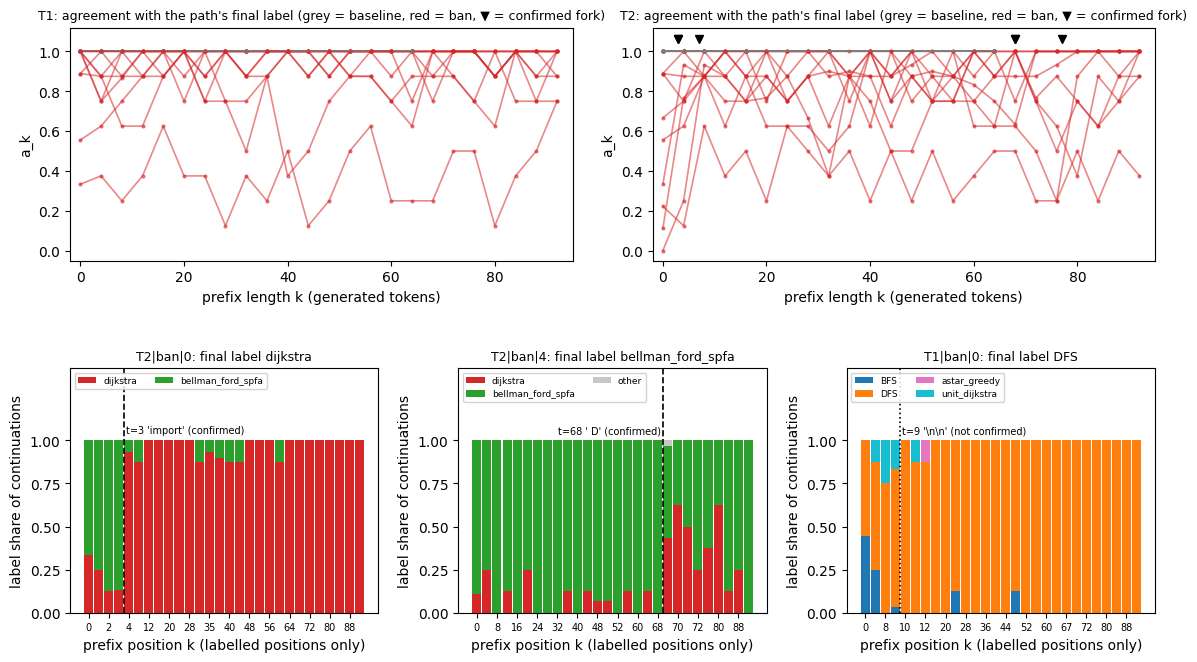

In [34]:
PAL = {"BFS": "#1f77b4", "DFS": "#ff7f0e", "bidirectional_BFS": "#9467bd", "IDDFS": "#8c564b", "astar_greedy": "#e377c2",
       "unit_dijkstra": "#17becf", "dijkstra": "#d62728", "bellman_ford_spfa": "#2ca02c", "bidirectional_dijkstra": "#bcbd22",
       "floyd_warshall": "#7f7f7f", "dial": "#aec7e8", "other": "#c7c7c7", "no_code": "#000000"}
by_pos = collections.defaultdict(list)
for fname in ("screen", "localise", "confirm"):
    for r in R[fname]:
        by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
o0_labels = collections.defaultdict(list)
for r in R["pools"]:
    if r["sample_id"] != 0:
        o0_labels[f"{r['task']}|{r['condition']}|{r['paraphrase_id']}"].append(r["label_final"])

fig = plt.figure(figsize=(14, 7.6))
gs = fig.add_gridspec(2, 6, height_ratios=[1, 1.05], hspace=0.45, wspace=0.7)
for col, task in enumerate(("T1", "T2")):
    ax = fig.add_subplot(gs[0, 3 * col:3 * col + 3])
    for p in scr["paths"]:
        if p["task"] != task:
            continue
        ks = sorted(int(k) for k in p["agreement"])
        ax.plot(ks, [p["agreement"][str(k)] for k in ks], color="#d62728" if p["condition"] == "ban" else "#7f7f7f",
                alpha=0.55, lw=1.2, marker="o", ms=2)
        for t in p["confirmed_forks"]:
            ax.plot(t, 1.06, "v", color="k", ms=6)
    ax.set_ylim(-0.05, 1.12); ax.set_xlim(-2, 95)
    ax.set_title(f"{task}: agreement with the path's final label (grey = baseline, red = ban, ▼ = confirmed fork)",
                 fontsize=9)
    ax.set_xlabel("prefix length k (generated tokens)"); ax.set_ylabel("a_k")

show = [b for b in ("T2|ban|0", "T2|ban|4", "T1|ban|0") if b in keep]
forks_by = collections.defaultdict(list)
for f in scr["forks"]:
    forks_by[f["bp_id"]].append(f)
for col, bp in enumerate(show):
    ax = fig.add_subplot(gs[1, 2 * col:2 * col + 2])
    task = bp.split("|")[0]
    pos = sorted({p for (b, p) in by_pos if b == bp} | {0})
    labs = [o0_labels[bp] + by_pos.get((bp, 0), []) if p == 0 else by_pos[(bp, p)] for p in pos]
    cats = [c for c in CATS[task] if any(c in l for l in labs)]
    bottom = np.zeros(len(pos))
    for c in cats:
        share = np.array([l.count(c) / len(l) for l in labs])
        ax.bar(range(len(pos)), share, bottom=bottom, color=PAL.get(c, "#999"), width=0.9, label=c)
        bottom += share
    gen_ids = by_id[bp]["metadata_base_path"]["gen_token_ids"]
    for f in forks_by[bp]:
        if f["t"] in pos:
            i = pos.index(f["t"])
            ax.axvline(i + 0.5, color="k", ls="--" if f["confirmed"] else ":", lw=1.2)
            right = i > len(pos) / 2
            ax.text(i + (0.3 if right else 0.7), 1.04, f"t={f['t']} {tok.decode([gen_ids[f['t']]])!r}"
                    + (" (confirmed)" if f["confirmed"] else " (not confirmed)"), fontsize=7,
                    ha="right" if right else "left")
    step = max(1, len(pos) // 12)
    ax.set_xticks(range(0, len(pos), step)); ax.set_xticklabels([pos[i] for i in range(0, len(pos), step)], fontsize=7)
    ax.set_ylim(0, 1.42); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xlabel("prefix position k (labelled positions only)"); ax.set_ylabel("label share of continuations")
    ax.set_title(f"{bp}: final label {by_id[bp]['metadata_base_path']['label']}", fontsize=9)
    ax.legend(fontsize=6.5, loc="upper left", ncol=2, framealpha=0.85, bbox_to_anchor=(0.0, 1.0))
plt.show()

### Detector sensitivity, and what the ban does to the pools
* **Left:** T6. How often the change-point detector finds a planted change of a given size. At 0 the detection rate is the false-positive rate.
* **Right:** the labels of the freshly re-labelled pool programs (G1 baseline vs G2 ban, T = 1.0). Under the ban the banned algorithm does not simply disappear; most of its mass moves to one substitute.

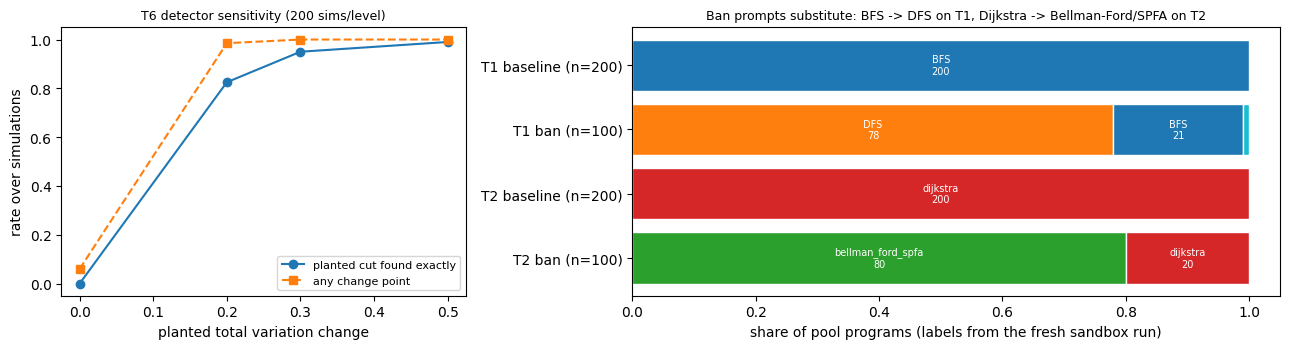

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
tvs = [tv for tv in t6 if tv != "note"]
axes[0].plot([float(t) for t in tvs], [t6[t]["detect_right_bracket"] for t in tvs], "o-", label="planted cut found exactly")
axes[0].plot([float(t) for t in tvs], [t6[t]["any_cp"] for t in tvs], "s--", label="any change point")
axes[0].set_xlabel("planted total variation change"); axes[0].set_ylabel("rate over simulations")
axes[0].set_title(f"T6 detector sensitivity ({T6_N_SIM} sims/level)", fontsize=9); axes[0].legend(fontsize=8)
ax = axes[1]
groups = [(t, c) for t in ("T1", "T2") for c in ("baseline", "ban")]
for i, (t, c) in enumerate(groups):
    sub = fresh_df[(fresh_df.task == t) & (fresh_df.condition == c)]
    left = 0.0
    for lab, n in sub["label"].value_counts().items():
        ax.barh(i, n / len(sub), left=left, color=PAL.get(lab, "#999"), edgecolor="w")
        if n / len(sub) > 0.06:
            ax.text(left + n / len(sub) / 2, i, f"{lab}\n{n}", ha="center", va="center", fontsize=7, color="w")
        left += n / len(sub)
ax.set_yticks(range(len(groups))); ax.set_yticklabels([f"{t} {c} (n={len(fresh_df[(fresh_df.task == t) & (fresh_df.condition == c)])})" for t, c in groups])
ax.invert_yaxis(); ax.set_xlabel("share of pool programs (labels from the fresh sandbox run)")
ax.set_title("Ban prompts substitute: BFS -> DFS on T1, Dijkstra -> Bellman-Ford/SPFA on T2", fontsize=9)
plt.tight_layout(); plt.show()

### Tables: recomputed readouts next to the stored run
* **Table A** is the paper's Table 18 (resampling screen).
* **Table B** is Table 19 (confirmed forking tokens).
* **Table C** is context from the stored run that this notebook does not recompute: the temperature sweep and the knob arms.

In [36]:
agg_stored = stored["screen_aggregate"]
rows = []
for g, a in scr["aggregate"].items():
    rows.append({"group": g, "paths": a["n_paths"], "R0 (decided at R)": round(a["R0"][0], 2),
                 "fixed by 0/8/16/32/64": " / ".join(f"{a['fixed_by'][k][0]:.1f}" for k in ("0", "8", "16", "32", "64")),
                 "not fixed": a["n_nonfixed"], "candidates": a["n_candidates"], "confirmed": a["n_confirmed"],
                 "F1": None if a["F1"] is None else round(a["F1"][0], 3), "F2": a["F2_median"],
                 "F3 (control FP)": None if a["F3"] is None else round(a["F3"][0], 3),
                 "final labels": a["label_counts_final"],
                 "same as stored": json.loads(json.dumps(a)) == agg_stored.get(g)})
print("Table A - resampling screen (Wilson point estimates)")
display(pd.DataFrame(rows))

stored_forks = {(f["bp_id"], f["t"]): f for f in stored["confirmed_forks"]}
rows = []
for f in scr["forks"]:
    if not f["confirmed"]:
        continue
    s = stored_forks.get((f["bp_id"], f["t"]), {})
    rows.append({"base path": f["bp_id"], "t": f["t"], "token": repr(f["token"]), "token type": f["token_type"],
                 "TVD": round(f["tvd"], 3), "stored TVD": round(s["tvd"], 3) if s else None,
                 "perm p": round(f["p_perm"], 4), "sharpness": round(f["sharpness"], 2),
                 "outcome entropy before/after (bits)": f"{abs(f['outcome_entropy_before_bits']):.3f} / {abs(f['outcome_entropy_after_bits']):.3f}",  # abs: -0.0
                 "next-token entropy (bits)": None if f["next_token_entropy_bits"] is None else round(f["next_token_entropy_bits"], 3),
                 "precedes commitment": f["precedes_commit"]})
print("Table B - confirmed forking tokens")
display(pd.DataFrame(rows))
print("controls:", len(scr["controls"]), "positions,", sum(c["false_positive"] for c in scr["controls"]), "false positives;",
      "mean next-token entropy (bits) at confirmed forks vs controls:",
      {k: (round(v, 3) if isinstance(v, float) else v) for k, v in scr["entropy"].items()})

rows = []
for task in ("T1", "T2"):
    for name, arm in (("global T=0.3", "G3_T0.3"), ("global T=0.7", "G3_T0.7"), ("global T=1.0", "G1"), ("global T=1.3", "G3_T1.3")):
        s = stored["pools_summary"][f"{task}|{arm}"]
        rows.append({"task": task, "arm": name, "n": s["n"], "labels": s["label_counts"], "pass": round(s["pass_rate"][0], 3),
                     "Hill_cc": round(s["hill_cc"], 3)})
    for name in ("FORK", "RANDOM_WINDOW", "ANCHORED"):
        s = stored["knob_table_summary"][task][name]
        rows.append({"task": task, "arm": f"knob {name}", "n": s["n"], "labels": s["label_counts"],
                     "pass": round(s["pass_rate"][0], 3), "Hill_cc": round(s["hill_cc"], 3)})
print("Table C - stored run, baseline prompt: global temperature sweep and the S11 knob arms (not recomputed here)")
display(pd.DataFrame(rows))
print("K1 (Hill_cc FORK - RANDOM_WINDOW, 95% cluster-bootstrap CI):",
      {t: (round(c["K1_fork_minus_random_window"]["diff"], 3), [round(x, 3) for x in c["K1_fork_minus_random_window"]["ci"]])
       for t, c in stored["knob_contrasts"].items()})

Table A - resampling screen (Wilson point estimates)


,group,paths,R0 (decided at R),fixed by 0/8/16/32/64,not fixed,candidates,confirmed,F1,F2,F3 (control FP),final labels,same as stored
0,T1|baseline,10,1.0,1.0 / 1.0 / 1.0 / 1.0 / 1.0,0,0,0,NaN,NaN,NaN,{'BFS': 10},True
1,T1|ban,10,0.8,0.3 / 0.3 / 0.5 / 0.5 / 0.5,7,3,0,0.000,NaN,0.0,"{'DFS': 9, 'BFS': 1}",True
2,T2|baseline,10,1.0,1.0 / 1.0 / 1.0 / 1.0 / 1.0,0,0,0,NaN,NaN,NaN,{'dijkstra': 10},True
3,T2|ban,10,0.4,0.0 / 0.1 / 0.1 / 0.1 / 0.3,10,10,6,0.500,1.0,0.0,"{'dijkstra': 4, 'bellman_ford_spfa': 6}",True
4,pooled|baseline,20,1.0,1.0 / 1.0 / 1.0 / 1.0 / 1.0,0,0,0,NaN,NaN,NaN,"{'BFS': 10, 'dijkstra': 10}",True
5,pooled|ban,20,0.6,0.1 / 0.2 / 0.3 / 0.3 / 0.4,17,13,6,0.294,1.0,0.0,"{'DFS': 9, 'dijkstra': 4, 'BFS': 1, 'bellman_ford_spfa': 6}",True


Table B - confirmed forking tokens


,base path,t,token,token type,TVD,stored TVD,perm p,sharpness,outcome entropy before/after (bits),next-token entropy (bits),precedes commitment
0,T2|ban|0,3,'import',import_token,0.800,0.800,0.0005,1.33,0.567 / 0.353,0.612,True
1,T2|ban|1,3,'import',import_token,0.767,0.767,0.0005,1.17,0.000 / 0.784,0.462,True
2,T2|ban|1,77,' BFS',identifier,0.333,0.333,0.0135,0.53,1.000 / 0.650,1.373,False
3,T2|ban|3,68,' Bell',identifier,0.333,0.333,0.0020,0.91,0.948 / 0.211,1.494,False
4,T2|ban|4,68,' D',identifier,0.467,0.533,0.0005,1.87,0.000 / 1.170,1.268,False
5,T2|ban|7,7,'\n',whitespace_newline,0.900,0.900,0.0005,1.32,0.211 / 0.353,0.130,False


controls: 10 positions, 0 false positives; mean next-token entropy (bits) at confirmed forks vs controls: {'fork_next_token_entropy_mean_bits': 0.89, 'control_next_token_entropy_mean_bits': 0.017, 'n_fork': 6, 'n_control': 10, 'outcome_entropy_drop_mean_bits': -0.133}
Table C - stored run, baseline prompt: global temperature sweep and the S11 knob arms (not recomputed here)


,task,arm,n,labels,pass,Hill_cc
0,T1,global T=0.3,100,{'BFS': 100},0.910,1.0
1,T1,global T=0.7,100,{'BFS': 100},0.820,1.0
2,T1,global T=1.0,200,{'BFS': 200},0.910,1.0
3,T1,global T=1.3,100,{'BFS': 100},0.960,1.0
4,T1,knob FORK,100,{'BFS': 100},0.830,1.0
5,T1,knob RANDOM_WINDOW,100,{'BFS': 100},0.850,1.0
6,T1,knob ANCHORED,100,{'BFS': 100},0.850,1.0
7,T2,global T=0.3,100,{'dijkstra': 100},1.000,1.0
8,T2,global T=0.7,100,{'dijkstra': 100},1.000,1.0
9,T2,global T=1.0,200,{'dijkstra': 200},0.995,1.0


K1 (Hill_cc FORK - RANDOM_WINDOW, 95% cluster-bootstrap CI): {'T1': (0.0, [0.0, 0.0]), 'T2': (0.0, [0.0, 0.0])}


## What the numbers say
**Temperature.** Under the baseline prompt, temperature does not change the algorithm. Every pool at T = 0.3, 0.7, 1.0 and 1.3 is 100 % BFS on T1 and 100 % Dijkstra on T2 (Hill_cc = 1; Table C). So are the three knob arms: temperature 1.3 in a window around the forking tokens, in a random window, and right after the code fence.

**Baseline prompt.** The algorithm is fixed before the first generated token. All 20 baseline base paths are decided at R (R0 = 1.0) and fixed from k = 0 on. No change point or fork is found, although T6 shows the detector finds a 0.2 total-variation change at the exact position in 82.5 % of planted trials, with a 6 % false-positive rate.

**Ban prompt.** The outcome stays open longer:

* On T1, 8 of 10 paths are decided at R, but only 3 are fixed from k = 0. The 3 fork candidates all fail confirmation.
* On T2, 4 of 10 paths are decided at R. Six forking tokens are confirmed on 5 paths:
  * **The `import` token at t = 3 (twice).** After ```` ```python ```` the model usually writes `from` (85–90 %, leading to `from collections import deque`). The rarer `import` leads to `import heapq`, i.e. Dijkstra.
  * **Algorithm names written in comments:** ` Bell`(man-Ford) and ` D`(ijkstra) at t = 68, and ` BFS` at t = 77.
  * **A newline at t = 7.** A single `\n` after `from collections import deque` (1.8 % of the next-token mass) lets a second import, `import heapq`, follow.

  The 10 control positions give no false positive. The next-token entropy is about 0.9 bits at the confirmed forks against about 0.02 bits at the controls.

**What a ban does.** Banning the default does not produce new algorithms, it *substitutes* one: DFS for BFS (78 of 100 T1 ban programs) and Bellman-Ford/SPFA for Dijkstra (80 of 100).

**Verdict: INCONCLUSIVE.** The forks are real but rare:

* F1 = 5/17 ≈ 0.29 of the non-fixed ban paths have a confirmed fork, below the 0.5 the fork account needs.
* The fork-window temperature knob does not beat a random window. K1 = 0 with CI [0, 0] on both tasks, because every arm writes one algorithm.
* There is no probe evidence for D1, because the stored probe summary is empty.

**Summary.** Under the baseline prompt the algorithm is chosen at the read position. Under a ban, some paths stay open and occasionally fork at import or comment tokens, but not often enough to support the fork account. Raising the temperature around forking tokens added no algorithmic diversity.

**Differences from the stored run.** The stored `method_out.json` was written by a preliminary analysis run (18:29). After it, the labeller's AST rules were revised and all labels recomputed (19:35), and the judge adjudicated the disputed programs. The demo data holds those final labels, which explains every difference:

* **Agreement values.** On 5 T2 ban paths, 16 stored a_k values differ (section 10 lists them). 15 are higher by one to three relabelled continuations. One, on `T2|ban|9`, is lower because the judge relabels confirmation programs as `other`. Change points, confirmed forks and every aggregate in Table A are unchanged.
* **One fork TVD.** The fork of `T2|ban|4` at t = 68 has a TVD of 0.467 here against 0.533 stored. It is confirmed either way.
* **Next-token entropies.** They were computed by the `states` phase after the preliminary run, so they appear here but not in the stored table.